# Лабораторная работа №4. Байесовская сеть

**Цель:** научиться описывать зависимости между переменными с помощью байесовской сети, самостоятельно строить граф и делать вероятностный вывод, когда появляется новая информация. Понять, как признаки связаны друг с другом. 

**Данные:** [Stack Overflow Developer Survey 2026](https://survey.stackoverflow.co/2026) - ежегодный опрос разработчиков от Stack Overflow, 30 903 анкеты. Данные открытые, лежат в [репозитории опроса на GitHub](https://github.com/StackExchange/Survey/tree/main/packages/archive/2026), лицензия ODbL 1.0.

Тема - от чего зависит зарплата разработчика и как разработчики относятся к AI-инструментам. В анкете этого года много вопросов про AI: изучал ли человек AI за последний год, пользуется ли AI в работе, нравится ли ему это.

Разбиения на train и test здесь нет. Мы ничего не предсказываем и не считаем метрику качества: сеть описывает совместное распределение, и по ней мы отвечаем на вопросы вида P(A | B). Поэтому вероятности оцениваются по всем данным.

Сеть строим в библиотеке pgmpy.

План: 1) настройки; 2) данные; 3) подготовка данных; 4) вопросы; 5) граф; 6) условные вероятности; 7) вероятностный вывод; 8) эксперимент с evidence; 9) анализ структуры; 10) причинность; 11) итоги.

## 1. Настройки

In [1]:
# Установка библиотек - нужна один раз, если их ещё нет (раскомментировать и выполнить):
# %pip install numpy pandas matplotlib seaborn networkx "pgmpy>=1.1.2"

In [2]:
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
import seaborn as sns

# pgmpy при импорте выводит служебные предупреждения (об устаревшем модуле и о прогресс-баре), на результат они не влияют
warnings.filterwarnings("ignore", message=".*StructureScore.*")
warnings.filterwarnings("ignore", message="IProgress not found")
from pgmpy.inference import CausalInference, VariableElimination
from pgmpy.models import DiscreteBayesianNetwork
from pgmpy.ci_tests import ChiSquare
from pgmpy.parameter_estimator import DiscreteBayesianEstimator, DiscreteMLE
from pgmpy.structure_score import BIC, LogLikelihood

# данные: в data/ хранятся только нужные столбцы, полный файл опроса весит около 120 МБ
DATA_DIR = Path("data")
DATA_PATH = DATA_DIR / "survey_results_2026.csv"
SOURCE_URL = ("https://media.githubusercontent.com/media/StackExchange/Survey/main/"
              "packages/archive/2026/survey_results_public.csv")
COLUMNS = ["ResponseId", "Age", "Employment", "Country", "Education", "WorkExp",
           "LearnAI", "AISelect", "AISentiment", "JobSat", "ConvertedCompYearly"]

# очистка данных
SALARY_MIN = 1_000        # USD в год: меньше - явная ошибка ввода (меньше $85 в месяц)
SALARY_MAX = 1_000_000    # USD в год: больше - скорее всего лишние нули
MIN_WORK_AGE = 16         # раньше 16 лет профессиональный стаж почти невозможен

# дискретизация
EXP_BINS = [-1, 2, 9, 19, np.inf]   # опыт работы, лет: 0-2, 3-9, 10-19, 20+
JOBSAT_BINS = [-1, 5, 7, 10]        # удовлетворённость работой 0-10: 0-5, 6-7, 8-10
MIN_OBS = 30                        # минимум наблюдений на один столбец таблицы условных вероятностей

sns.set_theme()  # стандартное оформление графиков seaborn
pd.set_option("display.precision", 3)
pd.set_option("display.max_colwidth", 120)  # длинные подписи в таблицах показываем целиком

Пути к файлам и все границы (очистка, интервалы) вынесены в константы, почему они такие - в разделе 3. Случайности в работе нет, поэтому при каждом запуске результат один и тот же.

## 2. Данные

### 2.1. Загрузка

In [3]:
def load_survey() -> pd.DataFrame:
    # читает CSV из data/; если файла нет - скачивает полный файл опроса и оставляет нужные столбцы
    if not DATA_PATH.exists():
        DATA_DIR.mkdir(exist_ok=True)
        full = pd.read_csv(SOURCE_URL, usecols=COLUMNS, low_memory=False)
        full[COLUMNS].to_csv(DATA_PATH, index=False)
    return pd.read_csv(DATA_PATH)


survey = load_survey()
print(f"Анкет: {len(survey)}, столбцов: {survey.shape[1]}")
survey.head()

Анкет: 30903, столбцов: 11


,ResponseId,Age,Employment,Country,Education,WorkExp,LearnAI,AISelect,AISentiment,JobSat,ConvertedCompYearly
0,1,35-44 years old,"Independent contractor, freelancer, or self-employed",Sri Lanka,"Master's degree (M.A., M.S., M.Eng., MBA, etc.)",NaN,"Yes, on my own",General-purpose AI chat tools,Neutral,3.0,NaN
1,2,45-54 years old,Employed,Brazil,"Master's degree (M.A., M.S., M.Eng., MBA, etc.)",26.0,"Yes, on my own",I don’t use AI tools,NaN,8.0,NaN
2,3,65 years or older,Retired,Ukraine,"Master's degree (M.A., M.S., M.Eng., MBA, etc.)",37.0,No,NaN,NaN,NaN,10000.0
3,4,Under 18 years old,Student,United States of America,Primary/elementary school,1.0,"Yes, on my own",AI agents or automated workflows;AI coding assistants or coding agents;General-purpose AI chat tools,Neutral,NaN,NaN
4,5,45-54 years old,Employed,Germany,"Bachelor's degree (B.A., B.S., B.Eng., etc.)",26.0,"Yes, both on my own and at work",AI coding assistants or coding agents,Neutral,8.0,85296.0


**Вывод:** 30 903 анкеты. В исходном файле 212 столбцов, в `data/` оставили только 11 нужных. Пропуски видны уже в первых строках, ими займёмся в разделе 3.

### 2.2. Описание данных
Один объект - одна анкета, то есть один человек, прошедший опрос в 2026 году.

Столбцы, которые используем:

| Столбец | Вопрос анкеты | Значения |
|---|---|---|
| `Age` | Сколько вам лет? | группы: младше 18, 18-24, 25-34, ..., 65+ |
| `Employment` | Занятость | по найму, фриланс, студент, не работает, пенсия |
| `Country` | Страна проживания | 169 стран |
| `Education` | Образование | от школы до PhD |
| `WorkExp` | Сколько лет работаете профессионально? | число |
| `LearnAI` | Изучали ли AI за последний год? | нет / сам / на работе / и сам, и на работе |
| `AISelect` | Пользуетесь ли AI в работе? | несколько вариантов или "не использую" |
| `AISentiment` | Как относитесь к AI в работе? | от "очень хорошо" до "очень плохо" |
| `JobSat` | Насколько довольны работой? | 0-10 |
| `ConvertedCompYearly` | Годовой доход в долларах | число |

Какие зависимости можно ожидать заранее:
- зарплата зависит от страны и опыта;
- опыт зависит от возраста;
- изучение AI зависит от работодателя, а значит от страны и должности (опыта);
- отношение к AI может зависеть от опыта и от того, изучал ли человек AI;
- удовлетворённость работой зависит от зарплаты и от того, нравятся ли рабочие инструменты.

Дальше проверим это на данных.

## 3. Подготовка данных

### 3.1. Кого берём в выборку

In [4]:
# сколько анкет с каждым видом занятости и какая доля из них указала зарплату
employment = survey.groupby("Employment").agg(
    анкет=("ResponseId", "size"),
    доля_с_зарплатой=("ConvertedCompYearly", lambda s: s.notna().mean()),
)
employment.sort_values("анкет", ascending=False)

,анкет,доля_с_зарплатой
Employment,,
Employed,20259,0.535
"Independent contractor, freelancer, or self-employed",4607,0.373
Student,3139,0.125
Not employed,1742,0.220
Retired,607,0.194
I prefer not to say,549,0.104


**Вывод:** берём только тех, кто работает по найму (20 259 анкет) - у них доход действительно зарплата, и указывают её чаще всего (53%). Доход фрилансера нерегулярный и с зарплатой несравним, а у студентов, безработных и пенсионеров это вообще стипендия, пенсия или подработка.

In [5]:
employed = survey[survey["Employment"] == "Employed"]
has_salary = employed["ConvertedCompYearly"].notna()
no_salary = employed[~has_salary]
print(f"Работают по найму: {len(employed)}, указали зарплату: {has_salary.sum()} ({has_salary.mean():.0%})")
print(f"Не указали зарплату: {len(no_salary)}, из них не дошли до вопроса о стране: {no_salary['Country'].isna().mean():.0%}")

# отличаются ли те, кто указал зарплату: доля указавших по возрастным группам
employed.groupby("Age")["ConvertedCompYearly"].apply(lambda s: s.notna().mean()).rename("доля указавших зарплату")

Работают по найму: 20259, указали зарплату: 10837 (53%)
Не указали зарплату: 9422, из них не дошли до вопроса о стране: 64%


Age
18-24 years old       0.411
25-34 years old       0.516
35-44 years old       0.576
45-54 years old       0.583
55-64 years old       0.592
65 years or older     0.570
Prefer not to say     0.124
Under 18 years old    0.098
Name: доля указавших зарплату, dtype: float64

**Вывод:** 47% работающих по найму зарплату не указали, причём большинство из них (64%) просто бросили анкету раньше. Чем заполнять пропуск в главной переменной, нечем, поэтому оставляем только тех, кто зарплату указал.

Минус: молодые указывают зарплату реже (41% в 18-24 против 58% в 35-44), так что в выборке опытных людей немного больше, чем на самом деле. Общие вероятности из-за этого чуть сдвинуты в сторону опытных.

In [6]:
data = employed[has_salary].copy()
print(f"В выборке: {len(data)} человек")

В выборке: 10837 человек


### 3.2. Пропуски в остальных столбцах

In [7]:
data[COLUMNS].isna().mean().rename("доля пропусков").to_frame().query("`доля пропусков` > 0")

,доля пропусков
Education,4.614e-04
WorkExp,4.337e-03
LearnAI,2.768e-04
AISelect,1.471e-01
AISentiment,2.532e-01
JobSat,1.476e-03


Почти везде пропусков меньше 0.5%. Много их только в AI-вопросах: 15% в `AISelect` и 25% в `AISentiment`. Посмотрим, откуда они.

In [8]:
NO_AI = "I don\N{RIGHT SINGLE QUOTATION MARK}t use AI tools"  # вариант ответа "не использую AI" (в анкете типографский апостроф)
no_ai = data["AISelect"] == NO_AI  # выбран только этот вариант, без AI-инструментов

# кому анкета задавала вопрос об отношении к AI
ai_use = np.select(
    [no_ai, data["AISelect"].notna()],
    ["выбрали только 'не использую AI'", "используют AI"],
    default="нет ответа об использовании AI",
)
pd.crosstab(ai_use, data["AISentiment"].notna().map({True: "ответили", False: "нет ответа"}),
            rownames=["AISelect"], colnames=["AISentiment"])

AISentiment,нет ответа,ответили
AISelect,,
выбрали только 'не использую AI',1112,0
используют AI,38,8093
нет ответа об использовании AI,1594,0


**Вывод:** пропуски в `AISentiment` двух видов.

1 112 человек ответили "не использую AI", и анкета просто не стала спрашивать, как они к нему относятся. Это не потерянный ответ, поэтому для них сделаем отдельное состояние "Не использует".

Ещё 1 594 человека не ответили ни на один AI-вопрос - не дошли до этой части анкеты. Вот это уже настоящий пропуск. Те, кто AI использует, на вопрос об отношении ответили почти все.

In [9]:
# отличаются ли те, кто не дошёл до AI-вопросов, по зарплате и опыту
reached_ai = data["AISelect"].notna().map({True: "дошли до AI-вопросов", False: "не дошли"})
data.groupby(reached_ai)[["ConvertedCompYearly", "WorkExp"]].median().round(0)

,ConvertedCompYearly,WorkExp
AISelect,,
дошли до AI-вопросов,85296.0,13.0
не дошли,73923.0,11.0


**Вывод:** те, кто не дошёл до AI-вопросов, чуть менее опытные (11 лет против 13) и зарабатывают меньше ($74 тыс. против $85 тыс.). Разница небольшая. Строки с пропусками не выкидываем: pgmpy (библиотека для байесовских сетей) считает каждую таблицу по тем строкам, где известны сама переменная и её родители. Так у этих людей зарплата и опыт всё равно пойдут в дело, а в таблицу отношения к AI они просто не попадут.

### 3.3. Ошибочные значения

**Зарплата.** Stack Overflow переводит доход в доллары, но никак его не чистит.

In [10]:
salary = data["ConvertedCompYearly"]
print(salary.quantile([0, 0.01, 0.05, 0.5, 0.95, 0.99, 1]).round(0).to_string())
print(f"\nМеньше ${SALARY_MIN:,}: {(salary < SALARY_MIN).sum()}, больше ${SALARY_MAX:,}: {(salary > SALARY_MAX).sum()}")
data.loc[salary < SALARY_MIN, ["Country", "WorkExp", "ConvertedCompYearly"]].sort_values("ConvertedCompYearly").head()

0.00    1.000e+00
0.01    8.900e+01
0.05    4.099e+03
0.50    8.489e+04
0.95    2.459e+05
0.99    4.850e+05
1.00    3.000e+07

Меньше $1,000: 267, больше $1,000,000: 19


,Country,WorkExp,ConvertedCompYearly
26981,India,6.0,1.0
25341,Nigeria,3.0,1.0
10112,China,1.0,1.0
9118,Germany,5.0,1.0
2034,Viet Nam,12.0,1.0


**Вывод:** встречаются зарплаты от $1 до $30 млн в год. Меньше $1 000 в год (это меньше $85 в месяц) указали 267 человек - явные ошибки, например "$1" в Германии. Больше $1 млн - 19 человек, скорее всего лишние нули. Убираем и те, и другие (286 анкет, 2.6%).

In [11]:
data = data[data["ConvertedCompYearly"].between(SALARY_MIN, SALARY_MAX)]
print(f"После очистки зарплаты: {len(data)} человек")

После очистки зарплаты: 10551 человек


**Возраст и опыт.** Стаж не может быть больше, чем возраст минус 16 лет. Берём верхнюю границу возрастной группы: например, в 18-24 года больше 8 лет стажа быть не может.

In [12]:
# верхняя граница каждой возрастной группы анкеты; у "65 и старше" и "Prefer not to say" проверки нет
AGE_UPPER = {"Under 18 years old": 17, "18-24 years old": 24, "25-34 years old": 34,
             "35-44 years old": 44, "45-54 years old": 54, "55-64 years old": 64}

max_exp = data["Age"].map(AGE_UPPER) - MIN_WORK_AGE
impossible = data["WorkExp"] > max_exp
print(f"Опыт больше возможного для возраста: {impossible.sum()} анкет")
print(data.loc[impossible, ["Age", "WorkExp"]].value_counts().to_string())

Опыт больше возможного для возраста: 26 анкет
Age                 WorkExp
Under 18 years old  3.0        3
25-34 years old     20.0       2
35-44 years old     30.0       2
18-24 years old     18.0       1
                    35.0       1
35-44 years old     29.0       1
25-34 years old     21.0       1
                    22.0       1
                    19.0       1
55-64 years old     49.0       1
45-54 years old     40.0       1
35-44 years old     79.0       1
                    34.0       1
45-54 years old     41.0       1
35-44 years old     31.0       1
18-24 years old     58.0       1
25-34 years old     65.0       1
                    26.0       1
55-64 years old     50.0       1
18-24 years old     12.0       1
                    9.0        1
                    10.0       1


**Вывод:** нашлось 26 невозможных анкет, например 18-24 года и 58 лет стажа. Где именно ошибка, непонятно, поэтому удаляем их целиком. Это 0.2% выборки.

In [13]:
data = data[~impossible]
print(f"После проверки возраста и опыта: {len(data)} человек")

После проверки возраста и опыта: 10525 человек


### 3.4. Группировка данных (дискретизация)
Сеть в pgmpy (инструмент, который помогает строить модели того, как разные переменные влияют друг на друга, и делать на основе этого прогнозы) работает с дискретными переменными, поэтому числа (опыт, зарплату, удовлетворённость) разбиваем на интервалы, а страны объединяем в группы.

Вершины сети и их состояния:

In [14]:
STATES = {
    "Возраст": ["до 25", "25-34", "35-44", "45+"],
    "Регион": ["США", "Высокий доход", "Средний и низкий доход"],
    "Опыт": ["0-2", "3-9", "10-19", "20+"],
    "Изучение AI": ["Нет", "Сам", "На работе"],
    "Отношение к AI": ["Не использует", "Отрицательное", "Нейтральное", "Положительное"],
    "Зарплата": ["Низкая", "Средняя", "Высокая"],
    "Удовлетворённость": ["0-5", "6-7", "8-10"],
}
NODES = list(STATES)

**Возраст.** 45-54, 55-64 и 65+ объединяем в "45+", потому что старших мало, а 65+ совсем редкие. Несколько анкет "младше 18" добавляем к 18-24. "Prefer not to say" считаем пропуском.

In [15]:
AGE_GROUPS = {
    "Under 18 years old": "до 25", "18-24 years old": "до 25", "25-34 years old": "25-34",
    "35-44 years old": "35-44", "45-54 years old": "45+", "55-64 years old": "45+", "65 years or older": "45+",
}
data["Возраст"] = data["Age"].map(AGE_GROUPS)  # "Prefer not to say" -> NaN
data[["Age", "Возраст"]].value_counts(dropna=False).sort_index().rename("анкет")

Age                 Возраст
18-24 years old     до 25       784
25-34 years old     25-34      3612
35-44 years old     35-44      3655
45-54 years old     45+        1706
55-64 years old     45+         644
65 years or older   45+         107
Prefer not to say   NaN          13
Under 18 years old  до 25         4
Name: анкет, dtype: int64

**Вывод:** 4 группы, в самой маленькой ("до 25") 788 человек - достаточно. Не указали возраст 13 человек.

**Регион.** Стран больше сотни, у многих по несколько анкет. Группируем их по [классификации Всемирного банка](https://datahelpdesk.worldbank.org/knowledgebase/articles/906519) (уровень дохода страны) - так группы заданы со стороны, а не подогнаны под наши данные. США выделяем отдельно: это самая большая страна в опросе и с самыми высокими зарплатами.

In [16]:
# страны с высоким доходом по классификации Всемирного банка (2026), названия как в анкете; США - отдельная группа
HIGH_INCOME = [
    "Andorra", "Antigua and Barbuda", "Australia", "Austria", "Bahrain", "Barbados", "Belgium",
    "Brunei Darussalam", "Bulgaria", "Canada", "Chile", "Costa Rica", "Croatia", "Cyprus", "Czech Republic",
    "Denmark", "Estonia", "Finland", "France", "Germany", "Greece", "Guyana", "Hong Kong (S.A.R.)", "Hungary",
    "Iceland", "Ireland", "Isle of Man", "Israel", "Italy", "Japan", "Kuwait", "Latvia", "Lithuania",
    "Luxembourg", "Malta", "Monaco", "Netherlands", "New Zealand", "Norway", "Oman", "Panama", "Poland",
    "Portugal", "Qatar", "Republic of Korea", "Romania", "Russian Federation", "San Marino", "Saudi Arabia",
    "Singapore", "Slovakia", "Slovenia", "South Korea", "Spain", "Sweden", "Switzerland", "Taiwan",
    "Trinidad and Tobago", "United Arab Emirates", "United Kingdom of Great Britain and Northern Ireland",
    "Uruguay",
]


def to_region(country):
    if pd.isna(country) or country == "Nomadic":  # "Nomadic" - страна не определена
        return np.nan
    if country == "United States of America":
        return "США"
    if country in HIGH_INCOME:
        return "Высокий доход"
    return "Средний и низкий доход"


data["Регион"] = data["Country"].map(to_region)
data.groupby("Регион").agg(
    анкет=("ResponseId", "size"),
    стран=("Country", "nunique"),
    медиана_зарплаты=("ConvertedCompYearly", "median"),
    крупнейшие_страны=("Country", lambda s: ", ".join(s.value_counts().index[:4])),
).reindex(STATES["Регион"])

,анкет,стран,медиана_зарплаты,крупнейшие_страны
Регион,,,,
США,2643,1,155000.0,United States of America
Высокий доход,6316,52,79610.0,"Germany, United Kingdom of Great Britain and Northern Ireland, France, Canada"
Средний и низкий доход,1565,75,25923.0,"India, Ukraine, Brazil, Mexico"


**Вывод:** в США 2 643 человека и медиана $155 тыс. - вдвое больше, чем в остальных богатых странах ($80 тыс., 6 316 человек). В странах со средним и низким доходом 1 565 человек и медиана $26 тыс. Группа "Высокий доход" получилась пёстрой (и Швейцария, и Польша), но зато в каждой группе больше тысячи человек.

**Опыт.** Делим по ступеням карьеры: 0-2 года (junior), 3-9 (middle), 10-19 (senior), 20+. Границы выбраны по смыслу, а не по квантилям.

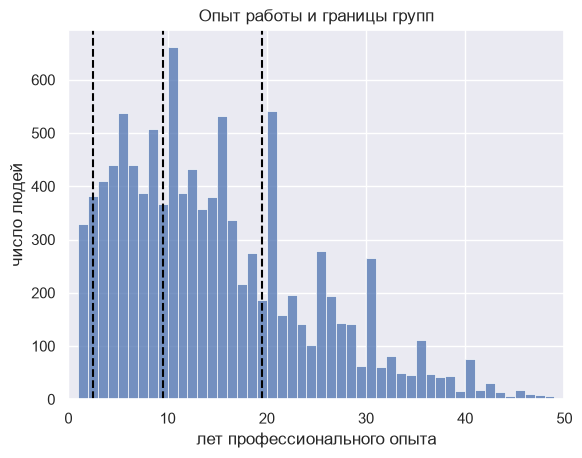

Опыт
0-2       711
3-9      3086
10-19    3762
20+      2925
Name: count, dtype: Int64

In [17]:
data["Опыт"] = pd.cut(data["WorkExp"], bins=EXP_BINS, labels=STATES["Опыт"]).astype("string")

ax = sns.histplot(data["WorkExp"], binwidth=1)
for edge in EXP_BINS[1:-1]:
    ax.axvline(edge + 0.5, color="black", linestyle="--")
ax.set(title="Опыт работы и границы групп", xlabel="лет профессионального опыта", ylabel="число людей", xlim=(0, 50))
plt.show()
data["Опыт"].value_counts().reindex(STATES["Опыт"])

**Вывод:** у большинства стаж от 3 до 20 лет, на гистограмме видны пики на круглых числах (10, 15, 20) - люди округляют. Новичков меньше всего (711), но этого хватает.

**Изучение AI.** "На работе" и "и сам, и на работе" объединяем: нам важно, участвует ли работодатель.

In [18]:
LEARN_GROUPS = {"No": "Нет", "Yes, on my own": "Сам",
                "Yes, at work": "На работе", "Yes, both on my own and at work": "На работе"}
data["Изучение AI"] = data["LearnAI"].map(LEARN_GROUPS)
data[["LearnAI", "Изучение AI"]].value_counts(dropna=False).sort_index().rename("анкет")

LearnAI                          Изучение AI
No                               Нет            1778
Yes, at work                     На работе      2316
Yes, both on my own and at work  На работе      5191
Yes, on my own                   Сам            1237
NaN                              NaN               3
Name: анкет, dtype: int64

**Вывод:** 71% изучали AI при участии работодателя, 17% не изучали, 12% учились сами.

**Отношение к AI.** Оценки сводим к трём: положительное, нейтральное, отрицательное ("Not sure" - к нейтральному, таких ответов мало). Плюс отдельное состояние "Не использует" для тех, кому вопрос не задавали.

In [19]:
SENTIMENT_GROUPS = {
    "Very favorable": "Положительное", "Somewhat favorable": "Положительное",
    "Neutral": "Нейтральное", "Not sure": "Нейтральное",
    "Somewhat unfavorable": "Отрицательное", "Very unfavorable": "Отрицательное",
}
no_ai = data["AISelect"] == NO_AI  # пересчитываем после очистки
data["Отношение к AI"] = data["AISentiment"].map(SENTIMENT_GROUPS).mask(no_ai, "Не использует")
data[["AISentiment", "Отношение к AI"]].value_counts(dropna=False).sort_index().rename("анкет")

AISentiment           Отношение к AI
Neutral               Нейтральное       1135
Not sure              Нейтральное         64
Somewhat favorable    Положительное     2477
Somewhat unfavorable  Отрицательное     1207
Very favorable        Положительное     2468
Very unfavorable      Отрицательное      543
NaN                   Не использует     1084
                      NaN               1547
Name: анкет, dtype: int64

**Вывод:** положительно к AI относятся 47%, отрицательно 17%, нейтрально 11%, не используют 10%. У 15% отношение неизвестно.

**Зарплата.** Делим на три равные части, чтобы в каждом состоянии была треть людей. Гистограмма в логарифмической шкале, потому что зарплаты отличаются в сотни раз.

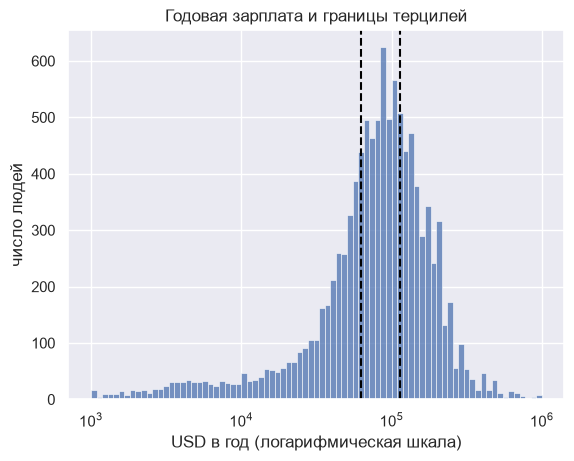

Границы: низкая < $62,550 <= средняя < $113,048 <= высокая


In [20]:
data["Зарплата"] = pd.qcut(data["ConvertedCompYearly"], q=3, labels=STATES["Зарплата"]).astype("string")
salary_edges = data["ConvertedCompYearly"].quantile([1 / 3, 2 / 3])

ax = sns.histplot(data["ConvertedCompYearly"], log_scale=True)
for edge in salary_edges:
    ax.axvline(edge, color="black", linestyle="--")
ax.set(title="Годовая зарплата и границы терцилей", xlabel="USD в год (логарифмическая шкала)", ylabel="число людей")
plt.show()
print(f"Границы: низкая < ${salary_edges.iloc[0]:,.0f} <= средняя < ${salary_edges.iloc[1]:,.0f} <= высокая")

**Вывод:** границы получились $62.5 тыс. и $113 тыс. в год. То есть "высокая" зарплата здесь - больше $113 тыс., и такая бывает в основном в США. Минус в том, что в "низкую" попадают и $5 тыс., и $60 тыс., разницу между ними сеть не увидит.

**Удовлетворённость.** Шкала 0-10, но чаще всего ставят 7-8, поэтому равные интервалы не подходят. Делим на 0-5, 6-7 и 8-10.

In [21]:
data["Удовлетворённость"] = pd.cut(data["JobSat"], bins=JOBSAT_BINS, labels=STATES["Удовлетворённость"]).astype("string")
print(data["JobSat"].value_counts(normalize=True).sort_index().round(3).to_string())
data["Удовлетворённость"].value_counts(normalize=True).reindex(STATES["Удовлетворённость"]).round(3)

JobSat
0.0     0.010
1.0     0.012
2.0     0.025
3.0     0.042
4.0     0.039
5.0     0.076
6.0     0.131
7.0     0.221
8.0     0.244
9.0     0.132
10.0    0.068


Удовлетворённость
0-5     0.204
6-7     0.352
8-10    0.444
Name: proportion, dtype: Float64

**Вывод:** недовольных 20%, средне - 35%, довольных 44%.

### 3.5. Итоговые данные для сети

In [22]:
bn_data = data[NODES].astype(object).where(data[NODES].notna(), np.nan)  # строки и NaN - формат, который понимает pgmpy

pd.DataFrame({
    "состояний": [len(STATES[node]) for node in NODES],
    "самое редкое состояние": [bn_data[node].value_counts().min() for node in NODES],
    "пропусков": bn_data.isna().sum().values,
}, index=NODES)

,состояний,самое редкое состояние,пропусков
Возраст,4,788,13
Регион,3,1565,1
Опыт,4,711,41
Изучение AI,3,1237,3
Отношение к AI,4,1084,1547
Зарплата,3,3500,0
Удовлетворённость,3,2147,15


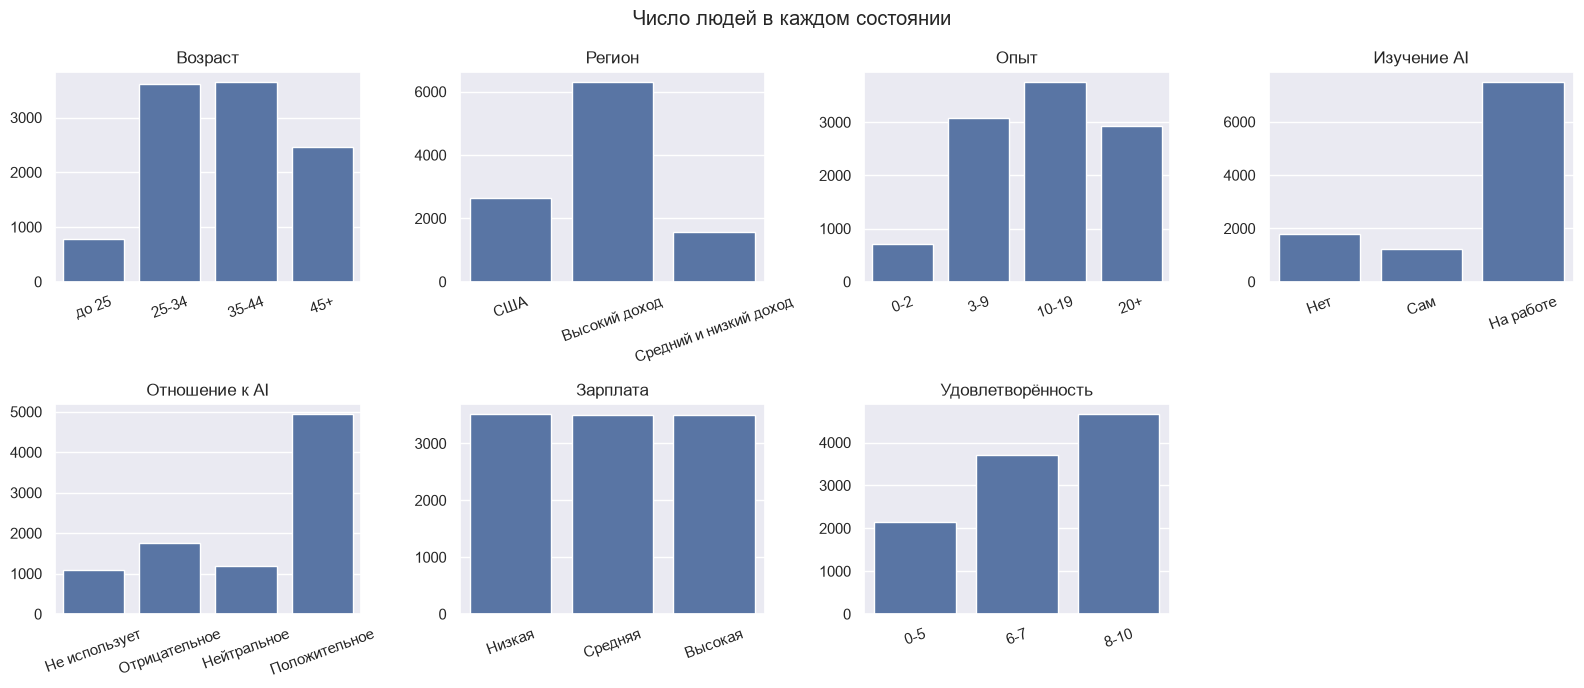

In [23]:
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, node in zip(axes.flat, NODES):
    sns.countplot(x=bn_data[node], order=STATES[node], ax=ax)
    ax.set(title=node, xlabel="", ylabel="")
    ax.tick_params(axis="x", rotation=20)
axes.flat[-1].axis("off")
fig.suptitle("Число людей в каждом состоянии")
fig.tight_layout()
plt.show()

**Вывод:** в выборке 10 525 человек, у каждой переменной 3-4 состояния, редких категорий не осталось (самое маленькое состояние - 711 человек). Пропусков много только в отношении к AI (1 547).

### 3.6. Достаточность наблюдений (размер CPT - таблицы условных вероятностей)
Каждый столбец таблицы условных вероятностей оценивается только по людям с одной конкретной комбинацией родителей. Будем ориентироваться на 30 человек: тогда вероятность оценивается с ошибкой около 0.09, а при 5 людях ошибка уже около 0.2.

Больше всего родителей будет у зарплаты. Проверим, сколько их можно себе позволить: кандидаты - регион, опыт, изучение AI и образование (сведём его к трём вариантам: ниже бакалавра, бакалавр, магистр и выше).

In [24]:
EDU_GROUPS = {
    "Primary/elementary school": "Ниже бакалавра",
    "Secondary school (e.g. American high school, German Realschule or Gymnasium, etc.)": "Ниже бакалавра",
    "Some college/university study without earning a degree": "Ниже бакалавра",
    "Associate degree (A.A., A.S., etc.)": "Ниже бакалавра",
    "Bachelor's degree (B.A., B.S., B.Eng., etc.)": "Бакалавр",
    "Master's degree (M.A., M.S., M.Eng., MBA, etc.)": "Магистр и выше",
    "Professional degree (JD, MD, Ph.D, Ed.D, etc.)": "Магистр и выше",
}  # "Other, please specify" -> пропуск
candidates = bn_data.assign(Образование=data["Education"].map(EDU_GROUPS))
STATES_EDU = {**STATES, "Образование": ["Ниже бакалавра", "Бакалавр", "Магистр и выше"]}


def parent_combo_counts(df, parents):
    # число наблюдений для каждой комбинации состояний родителей, включая комбинации без наблюдений
    full_index = pd.MultiIndex.from_product([STATES_EDU[p] for p in parents], names=parents)
    return df.groupby(parents).size().reindex(full_index, fill_value=0)


variants = {
    "Регион, Опыт, Изучение AI": ["Регион", "Опыт", "Изучение AI"],
    "+ Образование": ["Регион", "Опыт", "Изучение AI", "Образование"],
}
rows = {}
for name, parents in variants.items():
    counts = parent_combo_counts(candidates, parents)
    rows[name] = {"комбинаций родителей": len(counts), "минимум наблюдений": counts.min(),
                  "медиана": int(counts.median()), f"комбинаций < {MIN_OBS}": (counts < MIN_OBS).sum()}
pd.DataFrame(rows).T

,комбинаций родителей,минимум наблюдений,медиана,комбинаций < 30
"Регион, Опыт, Изучение AI",36,20,134,2
+ Образование,108,3,42,46


**Вывод:** с тремя родителями у зарплаты 36 комбинаций, в самой маленькой 20 человек, меньше 30 только в двух. С образованием комбинаций стало бы 108, и в 46 из них было бы меньше 30 человек (в самой маленькой всего 3). Поэтому образование в сеть не берём, и влияние диплома на зарплату сеть показать не сможет.

## 4. Вопросы к сети
Вопросы и ожидания записаны до того, как строили граф и считали вероятности.

**1. Связано ли изучение AI с высокой зарплатой?** Сравним P(Зарплата = Высокая) и P(Зарплата = Высокая | Изучение AI), потом то же самое при известных регионе и опыте. Ожидаем, что у тех, кто изучал AI на работе, высокая зарплата чаще, но при известных регионе и опыте разница станет меньше.

**2. Кто лучше относится к AI - новички или опытные?** Сравним P(Отношение к AI | Опыт = 0-2) и P(Отношение к AI | Опыт = 20+). Ожидаем, что новички, которые сразу начинали работать с AI, относятся к нему лучше.

**3. Что сильнее связано с удовлетворённостью работой - зарплата или отношение к AI?** Смотрим P(Удовлетворённость = 8-10) при разных значениях. Ожидаем, что зарплата важнее.

**4. Что можно сказать о человеке, если знаем только, что у него высокая зарплата?** Это вывод в обратную сторону, от следствия к причинам: P(Регион = США | Зарплата = Высокая). Ожидаем, что в основном это США.

## 5. Граф сети (DAG - направленный ациклический граф)

### 5.1. Рёбра
Ребро A -> B значит, что мы считаем, будто A напрямую влияет на B. Направление выбираем по смыслу и по времени: причина появляется раньше следствия.

| Ребро | Почему связаны | Почему в эту сторону |
|---|---|---|
| Регион -> Возраст | в странах со средним доходом IT-отрасль молодая, и разработчики там моложе | от страны зависит возрастной состав, наоборот - слабо |
| Возраст -> Опыт | стаж копится с годами | стаж не меняет возраст |
| Опыт -> Изучение AI | новички чаще учатся сами, опытных чаще обучают на работе | изучение AI не меняет стаж |
| Регион -> Изучение AI | в богатых странах компании раньше внедряют AI и платят за обучение | изучение AI не меняет страну |
| Регион -> Зарплата | уровень зарплат в стране | страна задаёт зарплату (обратное - переезд, см. раздел 10) |
| Опыт -> Зарплата | опытный специалист стоит дороже | зарплата не добавляет стаж |
| Изучение AI -> Зарплата | главная гипотеза: AI-навыки ценятся | спорно, может быть и наоборот (разделы 9 и 10) |
| Регион -> Отношение к AI | в богатых странах AI чаще ограничивают из-за безопасности, в странах со средним доходом он помогает конкурировать | отношение не меняет страну |
| Опыт -> Отношение к AI | новички и опытные по-разному работают с AI, в какую сторону - вопрос 2 | отношение не меняет стаж |
| Изучение AI -> Отношение к AI | кто изучал AI, лучше видит пользу | спорно: кому AI нравится, тот охотнее его изучает |
| Зарплата -> Удовлетворённость | деньги важны для удовлетворённости | удовлетворённость сама зарплату не поднимает |
| Отношение к AI -> Удовлетворённость | с приятными инструментами работать приятнее | удовлетворённость - общая оценка, отношение к AI - её часть |

Чего в графе нет:
- возраст не связан напрямую с зарплатой, изучением AI и отношением к AI - считаем, что он действует через опыт (проверим в разделе 9);
- регион с опытом связан только через возраст;
- регион, опыт и изучение AI влияют на удовлетворённость только через зарплату и отношение к AI;
- между зарплатой и отношением к AI ребра нет, прямой причины для такой связи не видно.

### 5.2. Построение сети (факторизация и число параметров)

In [25]:
EDGES = [
    ("Регион", "Возраст"), ("Возраст", "Опыт"),
    ("Опыт", "Изучение AI"), ("Регион", "Изучение AI"),
    ("Регион", "Зарплата"), ("Опыт", "Зарплата"), ("Изучение AI", "Зарплата"),
    ("Регион", "Отношение к AI"), ("Опыт", "Отношение к AI"), ("Изучение AI", "Отношение к AI"),
    ("Зарплата", "Удовлетворённость"), ("Отношение к AI", "Удовлетворённость"),
]
model = DiscreteBayesianNetwork(EDGES)  # pgmpy не даст добавить ребро, которое создаёт цикл
print(f"Вершин: {len(model.nodes())}, рёбер: {len(model.edges())}, "
      f"ориентированный ациклический граф: {nx.is_directed_acyclic_graph(model)}")


def n_parent_combos(node):
    # число комбинаций состояний родителей = число столбцов в таблице условных вероятностей
    return int(np.prod([len(STATES[parent]) for parent in model.get_parents(node)]))


structure = pd.DataFrame({
    "родители": [", ".join(model.get_parents(node)) or "-" for node in NODES],
    "комбинаций родителей": [n_parent_combos(node) for node in NODES],
    "параметров": [(len(STATES[node]) - 1) * n_parent_combos(node) for node in NODES],
}, index=NODES)
full_table = int(np.prod([len(STATES[node]) for node in NODES])) - 1
print(f"Параметров в сети: {structure['параметров'].sum()}, "
      f"в полной таблице совместного распределения: {full_table}")
structure

Вершин: 7, рёбер: 12, ориентированный ациклический граф: True
Параметров в сети: 251, в полной таблице совместного распределения: 5183


,родители,комбинаций родителей,параметров
Возраст,Регион,3,9
Регион,-,1,2
Опыт,Возраст,4,12
Изучение AI,"Опыт, Регион",12,24
Отношение к AI,"Регион, Опыт, Изучение AI",36,108
Зарплата,"Регион, Опыт, Изучение AI",36,72
Удовлетворённость,"Зарплата, Отношение к AI",12,24


**Вывод:** граф ациклический, корень один - регион. Больше всего родителей (по три) у зарплаты и отношения к AI. Вся сеть задаётся 251 числом, а полная таблица всех сочетаний 7 переменных потребовала бы 5 183 - на 10 525 анкет это по два человека на ячейку. В этом и смысл байесовской сети: каждая вершина зависит только от своих родителей.

Формально сеть записывает совместное распределение как произведение таблиц "вершина при родителях" (факторизация):

P(все 7 переменных) = P(Регион) * P(Возраст | Регион) * P(Опыт | Возраст) * P(Изучение AI | Регион, Опыт) * P(Зарплата | Регион, Опыт, Изучение AI) * P(Отношение к AI | Регион, Опыт, Изучение AI) * P(Удовлетворённость | Зарплата, Отношение к AI)

### 5.3. Рисунок
Сверху то, что от человека почти не зависит (страна, возраст), снизу - итоговая оценка работы.

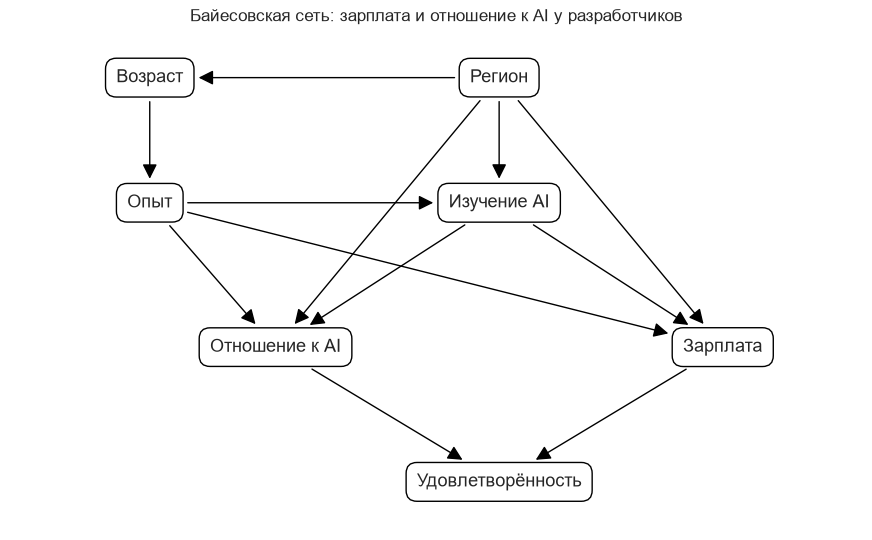

In [26]:
# координаты вершин на рисунке: сверху вниз от причин к следствиям
POS = {
    "Возраст": (0.5, 4.2), "Регион": (3, 4.2),
    "Опыт": (0.5, 2.9), "Изучение AI": (3, 2.9),
    "Отношение к AI": (1.4, 1.4), "Зарплата": (4.6, 1.4),
    "Удовлетворённость": (3, 0),
}


def draw_network(edges, title):
    fig, ax = plt.subplots(figsize=(11, 6.5))
    # подписи вершин в рамках; стрелки обрезаются по краю рамки (patchA, patchB), чтобы не заходить на текст
    boxes = {node: ax.text(x, y, node, ha="center", va="center", fontsize=13,
                           bbox=dict(boxstyle="round,pad=0.6", facecolor="white", edgecolor="black"))
             for node, (x, y) in POS.items()}
    for u, v in edges:
        ax.annotate("", xy=POS[v], xytext=POS[u],
                    arrowprops=dict(arrowstyle="-|>", mutation_scale=22, color="black", shrinkA=3, shrinkB=3,
                                    patchA=boxes[u].get_bbox_patch(), patchB=boxes[v].get_bbox_patch()))
    ax.set(xlim=(-0.5, 5.6), ylim=(-0.5, 4.7), title=title)
    ax.axis("off")
    plt.show()


draw_network(EDGES, "Байесовская сеть: зарплата и отношение к AI у разработчиков")

**Вывод:** регион - общий родитель возраста, изучения AI, зарплаты и отношения к AI, поэтому часть связей между ними может объясняться просто страной (это важно для вопроса 1). У зарплаты три родителя, и если зарплата известна, они начинают "объяснять" друг друга - это проверим в вопросе 4. Пересечения линий на рисунке ничего не значат.

### 5.4. Что утверждает граф (d-разделение)
Если ребра нет, граф утверждает, что при каких-то известных переменных другие становятся независимыми (d-разделённость). Проверим несколько таких утверждений, а соблюдаются ли они в данных - посмотрим в разделе 9.

In [27]:
CLAIMS = [
    ("Возраст", "Зарплата", []),
    ("Возраст", "Зарплата", ["Опыт", "Регион"]),
    ("Удовлетворённость", "Опыт", ["Зарплата", "Отношение к AI"]),
    ("Регион", "Опыт", ["Возраст"]),
    ("Регион", "Опыт", ["Возраст", "Зарплата"]),
]
pd.DataFrame(
    [(x, y, ", ".join(z) or "ничего", "зависимы" if model.is_dconnected(x, y, observed=z) else "независимы")
     for x, y, z in CLAIMS],
    columns=["переменная 1", "переменная 2", "известно", "по графу"],
)

,переменная 1,переменная 2,известно,по графу
0,Возраст,Зарплата,ничего,зависимы
1,Возраст,Зарплата,"Опыт, Регион",независимы
2,Удовлетворённость,Опыт,"Зарплата, Отношение к AI",независимы
3,Регион,Опыт,Возраст,независимы
4,Регион,Опыт,"Возраст, Зарплата",зависимы


**Вывод:** возраст связан с зарплатой, но если известны опыт и регион, он уже ничего не добавляет. Регион и опыт при известном возрасте независимы, но становятся зависимыми, если узнать зарплату: высокая зарплата при маленьком опыте намекает на США. Это пока утверждения модели, а не факты о данных.

## 6. Условные вероятности (CPT)

### 6.1. Оценка (MLE)
Оцениваем методом максимального правдоподобия (MLE): вероятность - это просто доля в данных. Например, P(Зарплата = Высокая | США, опыт 3-9, AI не изучал) - доля людей с высокой зарплатой среди таких американцев.

In [28]:
model.fit(bn_data, estimator=DiscreteMLE(state_names=STATES))  # state_names задаёт порядок состояний
print(f"Таблицы корректны (в каждом столбце сумма вероятностей = 1): {model.check_model()}")


def parent_index(parents):
    # все комбинации состояний родителей в том же порядке, что и столбцы таблицы pgmpy
    if len(parents) == 1:
        return pd.Index(STATES[parents[0]], name=parents[0])
    return pd.MultiIndex.from_product([STATES[p] for p in parents], names=parents)


def family_counts(node):
    # число наблюдений для каждой комбинации состояний родителей (строки, где известны вершина и родители)
    parents = model.get_cpds(node).variables[1:]  # порядок родителей как в таблице pgmpy
    family = bn_data[[node] + parents].dropna()
    if not parents:
        return family, pd.Series([len(family)])
    counts = family.groupby(parents[0] if len(parents) == 1 else parents).size()
    return family, counts.reindex(parent_index(parents), fill_value=0)


rows = {}
for node in NODES:
    family, counts = family_counts(node)
    rows[node] = {"строк для оценки": len(family), "столбцов в таблице": len(counts),
                  "минимум наблюдений в столбце": counts.min(), f"столбцов < {MIN_OBS}": (counts < MIN_OBS).sum()}
pd.DataFrame(rows).T

Таблицы корректны (в каждом столбце сумма вероятностей = 1): True


,строк для оценки,столбцов в таблице,минимум наблюдений в столбце,столбцов < 30
Возраст,10511,3,1563,0
Регион,10524,1,10524,0
Опыт,10471,4,775,0
Изучение AI,10480,12,150,0
Отношение к AI,8951,36,16,3
Зарплата,10480,36,20,2
Удовлетворённость,8971,12,298,0


**Вывод:** все таблицы корректны. Отношение к AI посчитано по 8 951 строке, остальные - по 8 971-10 524. Маленьких столбцов мало: у отношения к AI три столбца меньше 30 человек (минимум 16), у зарплаты два (минимум 20). Это редкие сочетания вроде американских новичков, изучавших AI сами, на них выводы строить не будем.

### 6.2. Сверка с данными (проверка модели)
Проверим, что таблицы pgmpy совпадают с долями из `pd.crosstab`.

In [29]:
def cpd_table(node):
    # таблица условных вероятностей: строки - состояния вершины, столбцы - комбинации состояний родителей
    cpd = model.get_cpds(node)
    parents = cpd.variables[1:]
    columns = parent_index(parents) if parents else ["P"]
    return pd.DataFrame(cpd.get_values(), index=pd.Index(STATES[node], name=node), columns=columns)


def data_table(node, parents):
    # те же доли, посчитанные напрямую по данным
    family = bn_data[[node] + parents].dropna()
    if not parents:
        return family[node].value_counts(normalize=True).to_frame("P")
    return pd.crosstab(family[node], [family[p] for p in parents], normalize="columns")


differences = {}
for node in NODES:
    table = cpd_table(node)
    parents = [] if table.columns.names == [None] else list(table.columns.names)
    direct = data_table(node, parents).reindex(index=table.index, columns=table.columns)
    differences[node] = np.abs(table - direct).max().max()
pd.Series(differences, name="макс. расхождение с данными").to_frame()

,макс. расхождение с данными
Возраст,0.0
Регион,0.0
Опыт,0.0
Изучение AI,0.0
Отношение к AI,0.0
Зарплата,0.0
Удовлетворённость,0.0


**Вывод:** совпадают полностью. Значит, MLE - это действительно частоты, и пропуски обработаны так, как мы хотели.

### 6.3. Важные таблицы

Возраст в зависимости от региона и опыт в зависимости от возраста:

In [30]:
display(cpd_table("Возраст").round(2))
cpd_table("Опыт").round(3)

Регион,США,Высокий доход,Средний и низкий доход
Возраст,,,
до 25,0.06,0.06,0.14
25-34,0.28,0.34,0.47
35-44,0.35,0.37,0.28
45+,0.31,0.23,0.11


Возраст,до 25,25-34,35-44,45+
Опыт,,,,
0-2,0.564,0.068,0.007,0.001
3-9,0.436,0.652,0.092,0.025
10-19,0.000,0.280,0.691,0.095
20+,0.000,0.000,0.210,0.879


**Вывод:** в странах со средним доходом 61% разработчиков моложе 35 лет, в США - 34%, ради этого и добавлено ребро Регион -> Возраст. В таблице опыта есть нули (например, 10+ лет стажа в "до 25") - это невозможные сочетания, такие нули правильные. Связь возраста с опытом не жёсткая: среди 35-44-летних у 10% стаж меньше 10 лет, видимо, пришли в профессию поздно.

Изучение AI в зависимости от региона и опыта:

In [31]:
learn = cpd_table("Изучение AI").T.reorder_levels(["Регион", "Опыт"]).reindex(parent_index(["Регион", "Опыт"]))
learn.round(2)

Изучение AI                    Нет   Сам  На работе
Регион                 Опыт                        
США                    0-2    0.27  0.13       0.60
                       3-9    0.22  0.07       0.72
                       10-19  0.15  0.06       0.79
                       20+    0.14  0.08       0.78
Высокий доход          0-2    0.33  0.13       0.54
                       3-9    0.22  0.09       0.68
                       10-19  0.15  0.10       0.75
                       20+    0.16  0.12       0.72
Средний и низкий доход 0-2    0.18  0.25       0.57
                       3-9    0.10  0.23       0.67
                       10-19  0.10  0.24       0.66
                       20+    0.09  0.21       0.70

**Вывод:** чем больше опыт, тем чаще AI изучали на работе (в США от 60% у новичков до 79%). В странах со средним доходом сами учатся в 2-3 раза чаще, чем в богатых, при любом опыте - видимо, там работодатели реже платят за обучение.

У зарплаты 36 столбцов, поэтому покажем вероятность высокой зарплаты тремя тепловыми картами, по одной на регион.

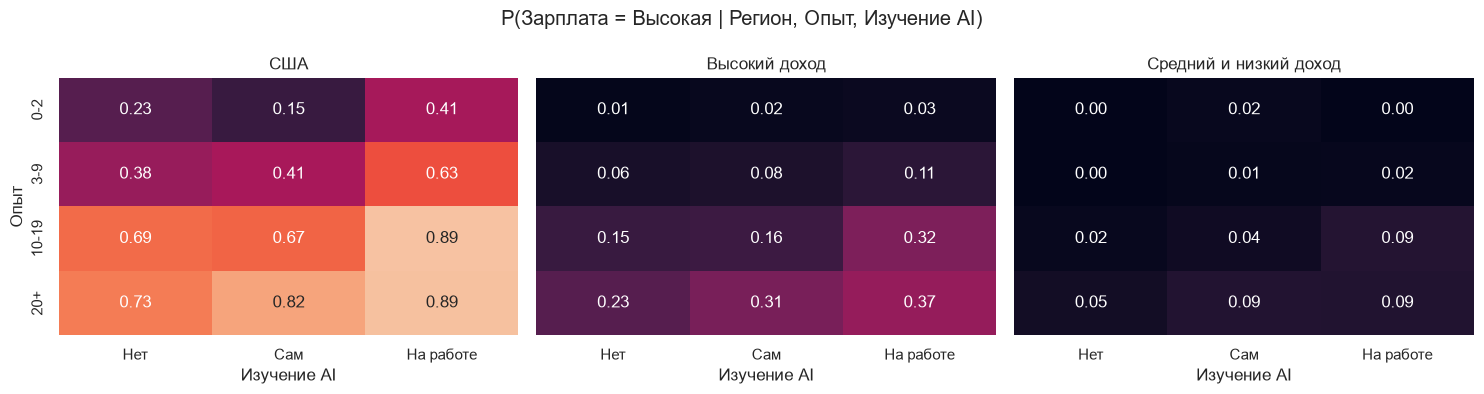

In [32]:
def heatmaps_by_region(node, state, title):
    # P(node = state | Регион, Опыт, Изучение AI): по одной тепловой карте на регион
    probs = cpd_table(node).loc[state]
    fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
    for ax, region in zip(axes, STATES["Регион"]):
        grid = (probs.xs(region, level="Регион").unstack("Изучение AI")
                .reindex(index=STATES["Опыт"], columns=STATES["Изучение AI"]))
        sns.heatmap(grid, annot=True, fmt=".2f", vmin=0, vmax=1, cbar=False, ax=ax)
        ax.set(title=region, xlabel="Изучение AI", ylabel="Опыт" if ax is axes[0] else "")
    fig.suptitle(title)
    fig.tight_layout()
    plt.show()


heatmaps_by_region("Зарплата", "Высокая", "P(Зарплата = Высокая | Регион, Опыт, Изучение AI)")

**Вывод:** сильнее всего на зарплату влияет регион: в США высокая зарплата бывает у 15-89% (смотря по опыту), в других богатых странах у 1-37%, в странах со средним доходом её почти нет. Дальше по силе - опыт.

Изучение AI на работе в США и других богатых странах везде даёт больше, чем "не изучал" (в США на 0.16-0.25). А вот самостоятельное изучение с зарплатой почти не связано: "Сам" то выше, то ниже, чем "Нет". Похоже, "на работе" говорит скорее о работодателе: обучение оплачивают крупные компании, которые и платят больше. Ячейка "США, 0-2, Сам" посчитана по 20 людям, ей доверять не стоит.

Отношение к AI: вероятность положительного отношения и вероятность, что человек AI не использует.

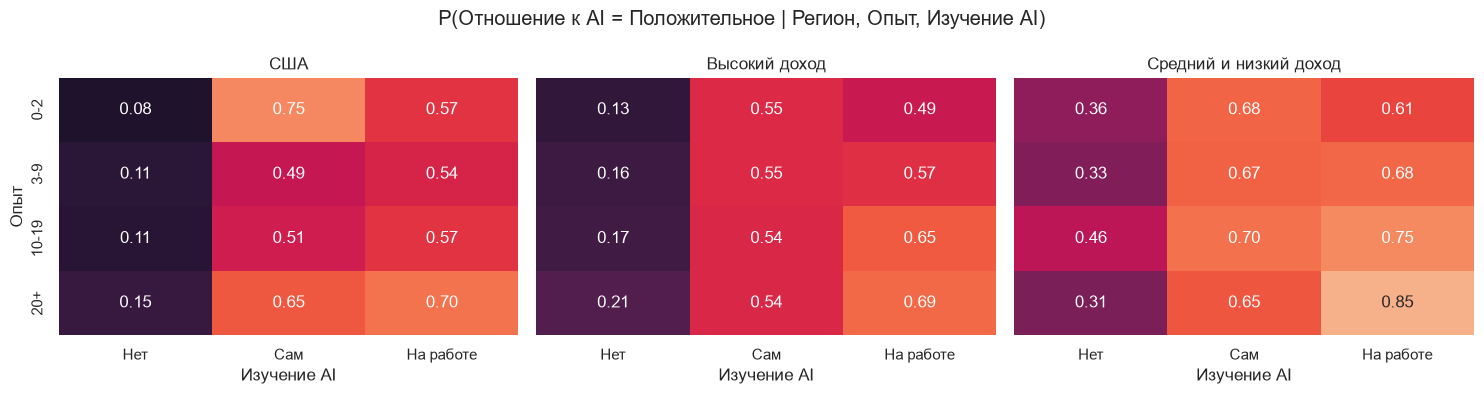

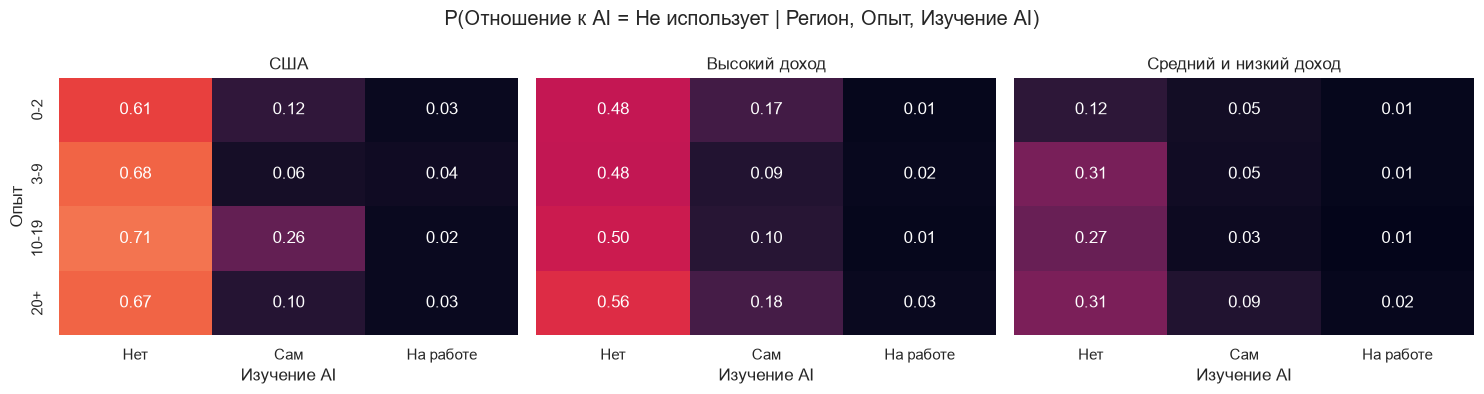

In [33]:
heatmaps_by_region("Отношение к AI", "Положительное", "P(Отношение к AI = Положительное | Регион, Опыт, Изучение AI)")
heatmaps_by_region("Отношение к AI", "Не использует", "P(Отношение к AI = Не использует | Регион, Опыт, Изучение AI)")

**Вывод:** кто AI не изучал, обычно им и не пользуется (в США 61-71%), а среди изучавших на работе не пользуются 1-4% - логично.

Неожиданно: с опытом отношение к AI становится лучше, а мы ждали обратного. Среди изучавших на работе в США положительных 0.57 у новичков и 0.70 у опытных, в странах со средним доходом 0.61 и 0.85. Возможно, опытному проще заметить ошибку AI и отдать ему рутину, а новичку трудно проверить ответ, и он больше боится, что AI заберёт его задачи.

Ещё одно: в странах со средним доходом даже не изучавшие AI относятся к нему намного лучше (положительно 31-46% против 8-21%). Ячейку "США, 0-2, Сам" (16 человек) не учитываем.

Доля довольных работой (8-10) в зависимости от зарплаты и отношения к AI:

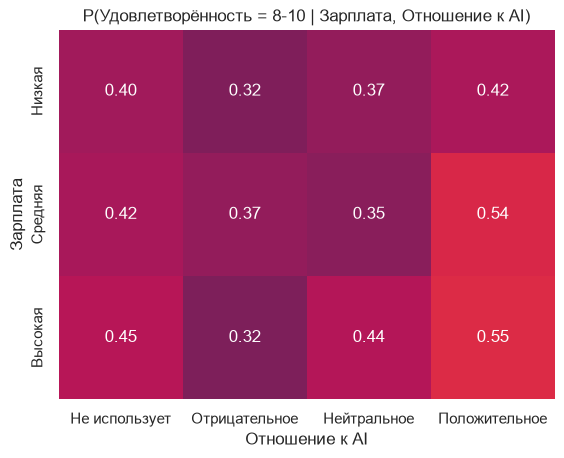

In [34]:
satisfied = (cpd_table("Удовлетворённость").loc["8-10"].unstack("Отношение к AI")
             .reindex(index=STATES["Зарплата"], columns=STATES["Отношение к AI"]))
ax = sns.heatmap(satisfied, annot=True, fmt=".2f", vmin=0, vmax=1, cbar=False)
ax.set(title="P(Удовлетворённость = 8-10 | Зарплата, Отношение к AI)")
plt.show()

**Вывод:** отношение к AI связано с удовлетворённостью сильнее зарплаты. При положительном отношении довольны 42-55%, при отрицательном - 32-37%, и у противников AI высокая зарплата не помогает (0.32 и при низкой, и при высокой). Это опять против нашего ожидания. Возможно, плохое отношение к AI часто значит, что его навязывает работодатель, и тогда это часть недовольства работой в целом.

### 6.4. Нули и маленькие столбцы (сглаживание Лапласа, K2)
MLE (методом максимального правдоподобия) ставит 0 каждому состоянию, которого не было в данных. Посмотрим, где это случилось.

In [35]:
rows = []
for node in NODES:
    if not model.get_parents(node):
        continue
    table = cpd_table(node)
    _, counts = family_counts(node)
    for state in table.index:
        for combo, value in table.loc[state].items():
            if value == 0:
                values = combo if isinstance(combo, tuple) else (combo,)
                condition = ", ".join(f"{p} = {v}" for p, v in zip(table.columns.names, values))
                rows.append({"вероятность": f"P({node} = {state} | {condition})", "наблюдений в столбце": counts[combo]})
pd.DataFrame(rows)

,вероятность,наблюдений в столбце
0,P(Опыт = 10-19 | Возраст = до 25),775
1,P(Опыт = 20+ | Возраст = до 25),775
2,P(Опыт = 20+ | Возраст = 25-34),3601
3,"P(Зарплата = Средняя | Изучение AI = Нет, Опыт = 0-2, Регион = Средний и низкий доход)",34
4,"P(Зарплата = Средняя | Изучение AI = Сам, Опыт = 0-2, Регион = Средний и низкий доход)",48
5,"P(Зарплата = Высокая | Изучение AI = Нет, Опыт = 0-2, Регион = Средний и низкий доход)",34
6,"P(Зарплата = Высокая | Изучение AI = Нет, Опыт = 3-9, Регион = Средний и низкий доход)",64
7,"P(Зарплата = Высокая | Изучение AI = На работе, Опыт = 0-2, Регион = Средний и низкий доход)",107


Нули бывают двух видов. В таблице опыта это невозможные сочетания, там всё правильно. А в таблице зарплаты нули у новичков из стран со средним доходом: среди 34-107 человек никто не получает много. На самом деле вероятность не ноль, просто в выборке таких не оказалось.

Сравним с оценкой со сглаживанием, чтобы понять, насколько это важно.                                                                                               Проводим тест на надежность модели.

In [36]:
# та же сеть со сглаживанием: к каждой ячейке таблицы добавляется одно "виртуальное" наблюдение (априорное распределение K2)
smoothed = DiscreteBayesianNetwork(EDGES)
smoothed.fit(bn_data, estimator=DiscreteBayesianEstimator(state_names=STATES, prior_type="K2"))

LARGE_COLUMN = 100  # столбцы, где наблюдений больше этого числа, считаем крупными

rows = {}
for node in NODES:
    # максимальное изменение вероятности в каждом столбце таблицы
    diff = np.abs(smoothed.get_cpds(node).get_values() - model.get_cpds(node).get_values()).max(axis=0)
    _, counts = family_counts(node)
    small = counts.values < LARGE_COLUMN
    rows[node] = {"макс. изменение": diff.max(),
                  f"в столбцах < {LARGE_COLUMN} наблюдений": diff[small].max() if small.any() else np.nan,
                  f"в столбцах >= {LARGE_COLUMN} наблюдений": diff[~small].max()}
pd.DataFrame(rows).T.round(3)

,макс. изменение,в столбцах < 100 наблюдений,в столбцах >= 100 наблюдений
Возраст,0.001,NaN,0.001
Регион,0.000,NaN,0.000
Опыт,0.002,NaN,0.002
Изучение AI,0.005,NaN,0.005
Отношение к AI,0.100,0.100,0.018
Зарплата,0.061,0.061,0.018
Удовлетворённость,0.001,NaN,0.001


**Вывод:**  Сглаживание Лапласа существенно меняет вероятности (до 10%) только в малочисленных группах (<100 наблюдений), устраняя нулевые значения там, где в выборке не было примеров. В крупных группах эффект пренебрежимо мал. В крупных столбцах вероятности меняются не больше чем на 0.02, в маленьких - до 0.1. Оставляем MLE: значения равны долям в данных, а наши запросы опираются в основном на крупные столбцы.

## 7. Вероятностный вывод (Variable Elimination)
Используем `VariableElimination` - точный вывод: он суммирует распределение сети по всем неизвестным переменным. Для каждого вопроса сравниваем вероятность без информации и с информацией.

Рядом показываем долю, посчитанную прямо по данным. Сеть выводит ответ из своих таблиц и графа, поэтому если ответ совпадает с данными, значит, допущения графа его не портят.

In [37]:
infer = VariableElimination(model)


def query(variable, evidence=None, engine=None):
    # распределение переменной при известных значениях других переменных (evidence);
    # engine - вывод по другой сети (нужно в разделе 9), по умолчанию основная сеть
    result = (engine or infer).query([variable], evidence=evidence or {}, show_progress=False)
    return pd.Series(result.values, index=result.state_names[variable], name=variable).reindex(STATES[variable])


def data_share(variable, state, evidence):
    # та же вероятность напрямую по данным: доля состояния среди людей с заданными значениями evidence
    rows = bn_data.dropna(subset=[variable, *evidence])
    for name, value in evidence.items():
        rows = rows[rows[name] == value]
    return (rows[variable] == state).mean(), len(rows)


def describe(evidence):
    return ", ".join(f"{name} = {value}" for name, value in evidence.items()) or "ничего"


def compare(variable, state, evidences):
    # P(variable = state | evidence) по сети и по данным для нескольких вариантов evidence
    rows = []
    for evidence in evidences:
        share, n = data_share(variable, state, evidence)
        rows.append({"известно": describe(evidence), f"P({variable} = {state})": query(variable, evidence)[state],
                     "по данным": share, "наблюдений": n})
    return pd.DataFrame(rows).set_index("известно")

### 7.1. Вопрос 1: связано ли изучение AI с высокой зарплатой?

In [38]:
compare("Зарплата", "Высокая", [{}] + [{"Изучение AI": state} for state in STATES["Изучение AI"]])

,P(Зарплата = Высокая),по данным,наблюдений
известно,,,
ничего,0.332,0.333,10525
Изучение AI = Нет,0.221,0.222,1778
Изучение AI = Сам,0.201,0.202,1237
Изучение AI = На работе,0.380,0.381,7507


**Вывод:** без информации высокая зарплата у трети. Если человек изучал AI на работе - 0.38, если сам - 0.20, если не изучал - 0.22. С данными совпадает.

Добавим ещё регион.

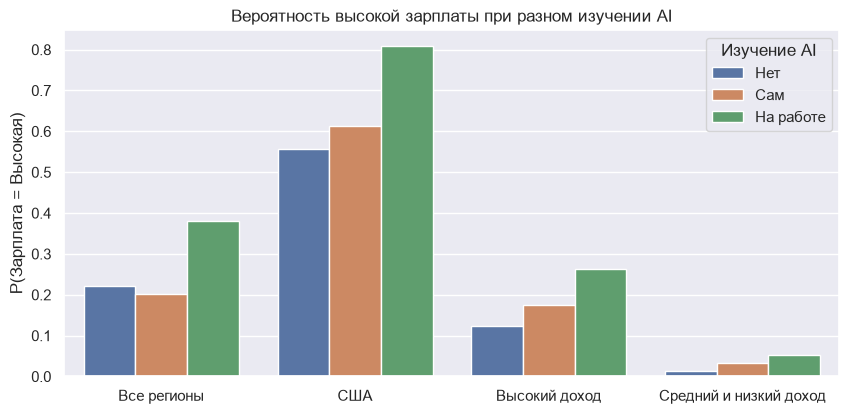

Изучение AI,Нет,Сам,На работе,На работе - Нет,Сам - Нет
регион,,,,,
Все регионы,0.221,0.201,0.380,0.159,-0.020
США,0.557,0.613,0.808,0.251,0.056
Высокий доход,0.123,0.176,0.264,0.141,0.053
Средний и низкий доход,0.013,0.034,0.053,0.040,0.021


In [39]:
rows = []
for region in ["Все регионы"] + STATES["Регион"]:
    for learn in STATES["Изучение AI"]:
        evidence = {"Изучение AI": learn} if region == "Все регионы" else {"Регион": region, "Изучение AI": learn}
        rows.append({"регион": region, "Изучение AI": learn, "P(Зарплата = Высокая)": query("Зарплата", evidence)["Высокая"]})
high_salary = pd.DataFrame(rows)

fig, ax = plt.subplots(figsize=(10, 4.5))
sns.barplot(data=high_salary, x="регион", y="P(Зарплата = Высокая)", hue="Изучение AI", hue_order=STATES["Изучение AI"], ax=ax)
ax.set(title="Вероятность высокой зарплаты при разном изучении AI", xlabel="")
plt.show()

table = high_salary.pivot(index="регион", columns="Изучение AI", values="P(Зарплата = Высокая)")
table = table.reindex(index=["Все регионы"] + STATES["Регион"], columns=STATES["Изучение AI"])
table["На работе - Нет"] = table["На работе"] - table["Нет"]
table["Сам - Нет"] = table["Сам"] - table["Нет"]
table.round(3)

**Вывод:** у изучавших AI на работе высокая зарплата чаще в каждом регионе: в США 0.81 против 0.56, в других богатых странах 0.26 против 0.12. То есть разница не уменьшилась, как мы ожидали, а в США даже выросла. С опытом то же самое (см. тепловую карту в 6.3).

А с самостоятельным изучением странно: в целом "Сам" чуть хуже, чем "Нет", а внутри каждого региона - чуть лучше. Это парадокс Симпсона, объяснение ниже.

In [40]:
# откуда люди с разным способом изучения AI: P(Регион | Изучение AI)
pd.DataFrame({learn: query("Регион", {"Изучение AI": learn}) for learn in STATES["Изучение AI"]}).T.round(3)

,США,Высокий доход,Средний и низкий доход
Нет,0.250,0.656,0.094
Сам,0.155,0.545,0.300
На работе,0.267,0.596,0.137


**Вывод:** среди самоучек 30% живут в странах со средним доходом, а среди не изучавших - 9%. Высокой зарплаты там почти нет, поэтому в целом у самоучек она реже. Если регион известен, перекос пропадает.

Ответ на вопрос 1: изучение AI на работе связано с высокой зарплатой в любом регионе и при любом опыте, самостоятельное - почти нет. Но это связь, а не доказательство, что обучение повышает зарплату (раздел 10).

### 7.2. Вопрос 2: кто лучше относится к AI - новички или опытные?

In [41]:
evidences = [{}, {"Опыт": "0-2"}, {"Опыт": "20+"},
             {"Опыт": "0-2", "Изучение AI": "На работе"}, {"Опыт": "20+", "Изучение AI": "На работе"}]
attitude = pd.DataFrame({describe(evidence): query("Отношение к AI", evidence) for evidence in evidences}).T
attitude["Положительное по данным"] = [data_share("Отношение к AI", "Положительное", evidence)[0] for evidence in evidences]
attitude.round(3)

,Не использует,Отрицательное,Нейтральное,Положительное,Положительное по данным
ничего,0.116,0.195,0.135,0.555,0.551
Опыт = 0-2,0.153,0.239,0.159,0.449,0.445
Опыт = 20+,0.121,0.142,0.121,0.616,0.614
"Опыт = 0-2, Изучение AI = На работе",0.016,0.264,0.180,0.541,0.542
"Опыт = 20+, Изучение AI = На работе",0.025,0.143,0.128,0.704,0.703


**Вывод:** ожидание не подтвердилось - опытные относятся к AI лучше. Положительно: 0.62 при стаже 20+ против 0.45 у новичков. И дело не в том, что опытных чаще обучают: среди изучавших AI на работе разница та же (0.70 против 0.54).

In [42]:
# то же внутри каждого региона: P(Отношение к AI = Положительное | Опыт, Изучение AI = На работе, Регион)
positive = pd.DataFrame({
    experience: {region: query("Отношение к AI", {"Опыт": experience, "Изучение AI": "На работе", "Регион": region})["Положительное"]
                 for region in STATES["Регион"]}
    for experience in ["0-2", "20+"]
})
positive["разница"] = positive["20+"] - positive["0-2"]
positive.round(3)

,0-2,20+,разница
США,0.573,0.704,0.130
Высокий доход,0.494,0.686,0.192
Средний и низкий доход,0.610,0.850,0.241


**Вывод:** внутри регионов разница даже больше: от 0.13 в США до 0.24 в странах со средним доходом. В целом она меньше, потому что среди новичков много людей из стран со средним доходом, где AI в целом любят больше.

Ответ на вопрос 2: опытные разработчики относятся к AI лучше новичков, и регион с изучением AI этого не объясняют.

### 7.3. Вопрос 3: что сильнее связано с удовлетворённостью - зарплата или отношение к AI?

In [43]:
compare("Удовлетворённость", "8-10", [
    {},
    {"Зарплата": "Низкая"}, {"Зарплата": "Высокая"},
    {"Отношение к AI": "Отрицательное"}, {"Отношение к AI": "Положительное"},
    {"Зарплата": "Высокая", "Отношение к AI": "Отрицательное"},
    {"Зарплата": "Низкая", "Отношение к AI": "Положительное"},
    {"Зарплата": "Высокая", "Отношение к AI": "Положительное"},
])

,P(Удовлетворённость = 8-10),по данным,наблюдений
известно,,,
ничего,0.447,0.444,10510
Зарплата = Низкая,0.393,0.387,3512
Зарплата = Высокая,0.482,0.484,3505
Отношение к AI = Отрицательное,0.336,0.338,1747
Отношение к AI = Положительное,0.506,0.508,4945
"Зарплата = Высокая, Отношение к AI = Отрицательное",0.317,0.317,568
"Зарплата = Низкая, Отношение к AI = Положительное",0.423,0.423,1536
"Зарплата = Высокая, Отношение к AI = Положительное",0.552,0.552,1825


**Вывод:** зарплата меняет долю довольных с 0.39 до 0.48, то есть на 0.09, а отношение к AI - с 0.34 до 0.51, почти вдвое сильнее. Высокая зарплата при плохом отношении к AI даёт 0.32 - меньше, чем низкая зарплата при хорошем (0.42).

Ответ на вопрос 3: отношение к AI связано с удовлетворённостью сильнее зарплаты, ожидание не подтвердилось. Хотя стрелку тут можно повернуть и наоборот: довольный работой человек может и к её инструментам относиться лучше.

### 7.4. Вопрос 4: что известно о человеке с высокой зарплатой? (эффект объяснения, explaining away)
Здесь идём против стрелок: по следствию (зарплате) оцениваем причины.

In [44]:
print("P(Регион | Зарплата = Высокая):")
print(query("Регион", {"Зарплата": "Высокая"}).round(3).to_string())
compare("Регион", "США", [
    {}, {"Зарплата": "Высокая"},
    {"Опыт": "0-2"}, {"Зарплата": "Высокая", "Опыт": "0-2"},
    {"Зарплата": "Высокая", "Опыт": "3-9"}, {"Зарплата": "Высокая", "Опыт": "20+"},
])

P(Регион | Зарплата = Высокая):
США                       0.568
Высокий доход             0.413
Средний и низкий доход    0.020


,P(Регион = США),по данным,наблюдений
известно,,,
ничего,0.251,0.251,10524
Зарплата = Высокая,0.568,0.569,3507
Опыт = 0-2,0.211,0.212,711
"Зарплата = Высокая, Опыт = 0-2",0.841,0.845,58
"Зарплата = Высокая, Опыт = 3-9",0.662,0.638,530
"Зарплата = Высокая, Опыт = 20+",0.557,0.571,1443


**Вывод:** если известно только, что зарплата высокая, вероятность США растёт с 0.25 до 0.57, ещё 0.41 - другие богатые страны. То есть США - чуть больше половины, а не "почти все".

Самое интересное - эффект объяснения. Опыт сам по себе почти не меняет вероятность США (0.21 у новичков). Но если высокая зарплата у новичка, это США с вероятностью 0.84, а если у человека с опытом 20+ - 0.56. Высокую зарплату новичка нечем объяснить, кроме страны. Сеть совпадает с данными, самое большое расхождение 0.024.

In [45]:
display(compare("Изучение AI", "На работе", [{}, {"Зарплата": "Низкая"}, {"Зарплата": "Высокая"}]))
pd.DataFrame({describe(evidence): query("Опыт", evidence) for evidence in [{}, {"Зарплата": "Высокая"}]}).T.round(3)

,P(Изучение AI = На работе),по данным,наблюдений
известно,,,
ничего,0.714,0.713,10522
Зарплата = Низкая,0.605,0.604,3516
Зарплата = Высокая,0.817,0.816,3507


,0-2,3-9,10-19,20+
ничего,0.068,0.295,0.358,0.279
Зарплата = Высокая,0.017,0.160,0.418,0.405


**Вывод:** среди людей с высокой зарплатой 82% изучали AI на работе (в среднем 71%), и почти все они опытные (10+ лет у 82%).

Ответ на вопрос 4: человек с высокой зарплатой - чаще всего опытный разработчик из США, которого учили AI на работе.

### 7.5. Ответы на вопросы

1. Изучение AI на работе связано с высокой зарплатой в любом регионе (в США 0.81 против 0.56), самостоятельное - почти нет. Ожидание подтвердилось наполовину: разница при известном регионе не уменьшилась.
2. Опытные относятся к AI лучше новичков (0.62 против 0.45). Ожидали обратного.
3. С удовлетворённостью сильнее связано отношение к AI (0.17), чем зарплата (0.09). Ожидали обратного.
4. Человек с высокой зарплатой из США с вероятностью 0.57, а если это новичок - 0.84. Ожидание подтвердилось.

Ответы сети везде отличаются от подсчёта по данным не больше чем на 0.024, то есть 251 параметра хватает, чтобы хорошо описать данные.

## 8. Эксперимент с evidence (с добавлением фактов)
Берём зарплату и по одной добавляем информацию о человеке: 25-34 года, страна с высоким доходом (например, Германия), опыт 3-9 лет, изучал AI на работе, доволен работой, к AI относится плохо.

Порядок такой, чтобы пройти по графу сверху вниз: сначала возраст (с зарплатой связан не напрямую), потом три родителя зарплаты, потом её ребёнок - удовлетворённость, и в конце отношение к AI, которое связано с зарплатой только через удовлетворённость.

In [46]:
PROFILE = {
    "Возраст": "25-34",
    "Регион": "Высокий доход",
    "Опыт": "3-9",
    "Изучение AI": "На работе",
    "Удовлетворённость": "8-10",
    "Отношение к AI": "Отрицательное",
}

steps, evidence = {"0. ничего не известно": {}}, {}
for i, (name, value) in enumerate(PROFILE.items(), start=1):
    evidence = {**evidence, name: value}
    steps[f"{i}. + {name} = {value}"] = evidence

salary_steps = pd.DataFrame({step: query("Зарплата", evidence) for step, evidence in steps.items()}).T
salary_steps["Высокая по данным"] = [data_share("Зарплата", "Высокая", evidence)[0] for evidence in steps.values()]
salary_steps["наблюдений"] = [data_share("Зарплата", "Высокая", evidence)[1] for evidence in steps.values()]
salary_steps.round(3)

,Низкая,Средняя,Высокая,Высокая по данным,наблюдений
0. ничего не известно,0.333,0.334,0.332,0.333,10525
1. + Возраст = 25-34,0.456,0.325,0.219,0.224,3612
2. + Регион = Высокий доход,0.441,0.415,0.144,0.140,2134
3. + Опыт = 3-9,0.496,0.405,0.099,0.101,1406
4. + Изучение AI = На работе,0.456,0.429,0.114,0.120,955
5. + Удовлетворённость = 8-10,0.412,0.462,0.126,0.155,393
6. + Отношение к AI = Отрицательное,0.429,0.465,0.106,0.121,58


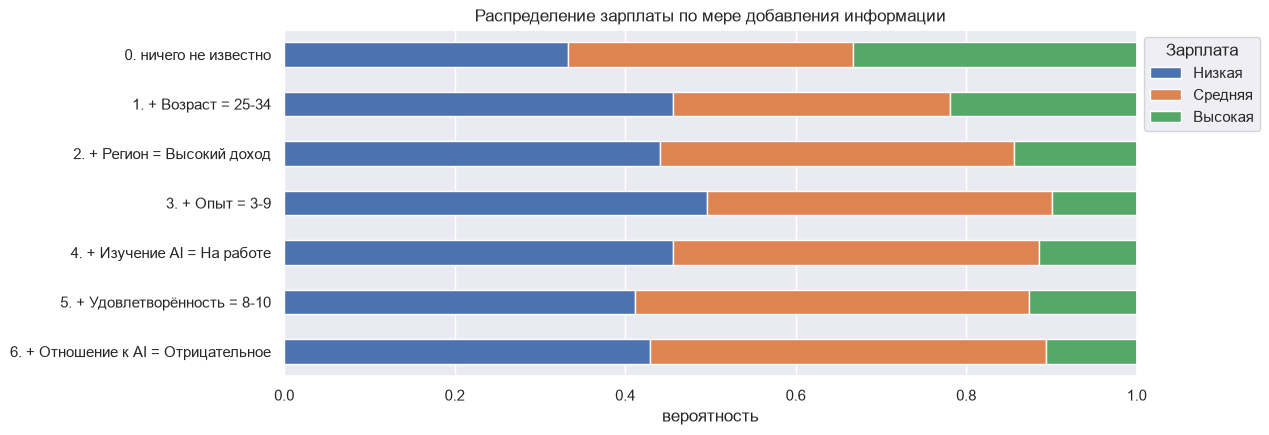

In [47]:
ax = salary_steps[STATES["Зарплата"]].plot.barh(stacked=True, figsize=(11, 4.5))
ax.invert_yaxis()  # шаг 0 сверху
ax.set(title="Распределение зарплаты по мере добавления информации", xlabel="вероятность", xlim=(0, 1))
ax.legend(title="Зарплата", bbox_to_anchor=(1, 1))
plt.show()

**Вывод:** каждое изменение объясняется графом.

Возраст 25-34 снижает вероятность высокой зарплаты с 0.33 до 0.22, хотя он и не родитель зарплаты: в этом возрасте мало опытных, и молодые чаще живут в странах со средним доходом. Дальше идут родители зарплаты: регион (0.14), опыт (0.10), изучение AI (0.11). Когда известны все три, распределение равно столбцу таблицы из раздела 6.3.

Удовлетворённость - ребёнок зарплаты, она влияет "снизу" через формулу Байеса: довольные чаще встречаются среди хорошо оплачиваемых, поэтому высокая зарплата растёт до 0.13. Отрицательное отношение к AI снова снижает её до 0.11, почему - в 8.2.

По данным на последнем шаге остаётся всего 58 человек, и посчитать долю напрямую уже нельзя надёжно, а сеть использует все анкеты.

### 8.1. Возраст перестаёт влиять, когда известен опыт (цепь и развилка)
Повторим первые шаги для трёх возрастов. По графу после того, как стали известны регион и опыт, возраст ничего не должен менять.

In [48]:
age_check = {}
for age in ["25-34", "35-44", "45+"]:
    age_check[age] = {
        "только возраст": query("Зарплата", {"Возраст": age})["Высокая"],
        "+ регион": query("Зарплата", {"Возраст": age, "Регион": "Высокий доход"})["Высокая"],
        "+ регион и опыт": query("Зарплата", {"Возраст": age, "Регион": "Высокий доход", "Опыт": "3-9"})["Высокая"],
    }
pd.DataFrame(age_check).round(3).rename_axis("P(Зарплата = Высокая), известно:")

,25-34,35-44,45+
"P(Зарплата = Высокая), известно:",,,
только возраст,0.219,0.386,0.488
+ регион,0.144,0.273,0.329
+ регион и опыт,0.099,0.099,0.099


**Вывод:** пока известен только возраст, разница большая (0.22 у 25-34 против 0.49 у 45+). После региона и опыта у всех ровно 0.099 - возраст отрезан от зарплаты. Так устроена модель, в данных это не совсем так (раздел 9).

### 8.2. Отношение к AI влияет на зарплату только через удовлетворённость (коллайдер)
Когда родители зарплаты известны, отношение к AI связано с ней только через общего ребёнка (Зарплата -> Удовлетворённость <- Отношение к AI). Пока удовлетворённость неизвестна, этот путь закрыт.

In [49]:
PARENTS = {name: PROFILE[name] for name in ["Регион", "Опыт", "Изучение AI"]}
collider_check = {
    "родители зарплаты": PARENTS,
    "+ Отношение к AI = Отрицательное": {**PARENTS, "Отношение к AI": "Отрицательное"},
    "+ Отношение к AI = Положительное": {**PARENTS, "Отношение к AI": "Положительное"},
    "+ Удовлетворённость = 8-10": {**PARENTS, "Удовлетворённость": "8-10"},
    "+ Удовлетворённость = 8-10, Отношение к AI = Отрицательное": {**PARENTS, "Удовлетворённость": "8-10", "Отношение к AI": "Отрицательное"},
    "+ Удовлетворённость = 8-10, Отношение к AI = Положительное": {**PARENTS, "Удовлетворённость": "8-10", "Отношение к AI": "Положительное"},
}
pd.Series({name: query("Зарплата", evidence)["Высокая"] for name, evidence in collider_check.items()},
          name="P(Зарплата = Высокая)").round(3).to_frame()

,P(Зарплата = Высокая)
родители зарплаты,0.114
+ Отношение к AI = Отрицательное,0.114
+ Отношение к AI = Положительное,0.114
+ Удовлетворённость = 8-10,0.126
"+ Удовлетворённость = 8-10, Отношение к AI = Отрицательное",0.106
"+ Удовлетворённость = 8-10, Отношение к AI = Положительное",0.129


**Вывод:** без удовлетворённости отношение к AI на зарплату не влияет - 0.114 при любом отношении. Как только удовлетворённость известна, путь открывается: 0.106 при плохом отношении и 0.129 при хорошем.

Почему так: у противников AI удовлетворённость от зарплаты почти не зависит (раздел 6.3), поэтому "доволен работой" про их зарплату ничего не говорит. А у тех, кто AI любит, довольные чаще получают больше.

### 8.3. Марковское одеяло зарплаты
Марковское одеяло вершины - это её родители, дети и другие родители её детей. Если все они известны, остальные вершины на неё уже не влияют.

У зарплаты в одеяло входят регион, опыт и изучение AI (родители), удовлетворённость (ребёнок) и отношение к AI (второй родитель удовлетворённости). Снаружи остаётся только возраст. Проверим: зафиксируем одеяло как в профиле из раздела 8 и будем менять возраст.

In [50]:
blanket = [node for node in NODES if node in model.get_markov_blanket("Зарплата")]
print("Марковское одеяло зарплаты:", ", ".join(blanket))

known = {node: PROFILE[node] for node in blanket}
blanket_check = {"одеяло известно": known}
for age in STATES["Возраст"]:
    blanket_check[f"+ Возраст = {age}"] = {**known, "Возраст": age}
pd.Series({name: query("Зарплата", evidence)["Высокая"] for name, evidence in blanket_check.items()},
          name="P(Зарплата = Высокая)").round(3).to_frame()

Марковское одеяло зарплаты: Регион, Опыт, Изучение AI, Отношение к AI, Удовлетворённость


,P(Зарплата = Высокая)
одеяло известно,0.106
+ Возраст = до 25,0.106
+ Возраст = 25-34,0.106
+ Возраст = 35-44,0.106
+ Возраст = 45+,0.106


**Вывод:** когда одеяло известно, вероятность высокой зарплаты одна и та же при любом возрасте (0.106). Это объединяет 8.1 и 8.2: родители закрывают путь от возраста, а удовлетворённость с отношением к AI нужны, потому что через общего ребёнка путь открывается. Для вывода о зарплате хватает пяти вершин одеяла, остальная сеть ничего не добавит.

## 9. Анализ структуры

### 9.1. Удаляем ребро Изучение AI -> Зарплата (повторная оценка)
На этом ребре держится вопрос 1. Удалим его, заново оценим таблицы и повторим запросы.

In [51]:
EDGES_WITHOUT = [edge for edge in EDGES if edge != ("Изучение AI", "Зарплата")]
model_without = DiscreteBayesianNetwork(EDGES_WITHOUT)
model_without.fit(bn_data, estimator=DiscreteMLE(state_names=STATES))
infer_without = VariableElimination(model_without)

QUERIES = (
    [("Зарплата", "Высокая", {"Изучение AI": learn}) for learn in STATES["Изучение AI"]]
    + [("Зарплата", "Высокая", {"Регион": "США", "Опыт": "3-9", "Изучение AI": learn}) for learn in STATES["Изучение AI"]]
    + [("Изучение AI", "На работе", {"Зарплата": "Высокая"})]
)
pd.DataFrame([
    {"запрос": f"P({variable} = {state} | {describe(evidence)})",
     "полная сеть": query(variable, evidence)[state],
     "без ребра": query(variable, evidence, engine=infer_without)[state],
     "по данным": data_share(variable, state, evidence)[0]}
    for variable, state, evidence in QUERIES
]).set_index("запрос").round(3)

,полная сеть,без ребра,по данным
запрос,,,
P(Зарплата = Высокая | Изучение AI = Нет),0.221,0.315,0.222
P(Зарплата = Высокая | Изучение AI = Сам),0.201,0.254,0.202
P(Зарплата = Высокая | Изучение AI = На работе),0.380,0.349,0.381
"P(Зарплата = Высокая | Регион = США, Опыт = 3-9, Изучение AI = Нет)",0.377,0.561,0.377
"P(Зарплата = Высокая | Регион = США, Опыт = 3-9, Изучение AI = Сам)",0.415,0.561,0.415
"P(Зарплата = Высокая | Регион = США, Опыт = 3-9, Изучение AI = На работе)",0.631,0.561,0.631
P(Изучение AI = На работе | Зарплата = Высокая),0.817,0.750,0.816


**Вывод:** результат изменился сильно. Разница между "на работе" и "не изучал" упала с 0.16 до 0.03, а при известных регионе и опыте пропала совсем (0.561 у всех). Небольшая разница осталась из-за обходных путей через регион и опыт: изучавшие AI на работе чаще опытные и реже живут в странах со средним доходом. Через эти пути объясняется только пятая часть связи.

Сеть без ребра хуже совпадает с данными: P(На работе | Высокая) 0.75 вместо 0.82. Структура влияет на вывод, потому что сеть хранит только таблицы "вершина при родителях": без ребра таблица зарплаты просто не может зависеть от изучения AI.

Сравним обе структуры по log-правдоподобию и BIC (это правдоподобие минус штраф за число параметров, чем больше, тем лучше). Берём только строки без пропусков, чтобы сравнивать на одних и тех же людях.

In [52]:
complete = bn_data.dropna()  # одни и те же строки для всех сравниваемых структур
log_likelihood, bic = LogLikelihood(complete, state_names=STATES), BIC(complete, state_names=STATES)
print(f"Строк без пропусков: {len(complete)}")


def structure_scores(edges):
    net = DiscreteBayesianNetwork(edges)
    n_params = sum((len(STATES[node]) - 1) * int(np.prod([len(STATES[p]) for p in net.get_parents(node)]))
                   for node in NODES)
    return {"log-правдоподобие": round(log_likelihood.score(net), 1), "параметров": n_params,
            "BIC": round(bic.score(net), 1)}


pd.DataFrame({"полная сеть": structure_scores(EDGES),
              "без ребра Изучение AI -> Зарплата": structure_scores(EDGES_WITHOUT)}).T.astype({"параметров": int})

Строк без пропусков: 8933


,log-правдоподобие,параметров,BIC
полная сеть,-58029.5,251,-59171.3
без ребра Изучение AI -> Зарплата,-58183.0,203,-59106.4


**Вывод:** с ребром правдоподобие выше на 153, то есть связь есть. Но ребро добавляет 48 параметров, а BIC штрафует за них на 218, и по BIC немного лучше сеть без ребра. Получается, даже нужно ли ребро, данные однозначно не говорят. Мы его оставляем: связь реальная (тест в 9.3), без неё сеть расходится с данными, а BIC против, скорее потому что таблица слишком подробная, а не потому что связи нет.

### 9.2. Можно ли понять направление рёбер по данным (марковская эквивалентность)
Сети эквивалентны по Маркову, если у них одинаковые рёбра без учёта направления и одинаковые V-структуры (A -> C <- B, где A и B не связаны). Такие сети одинаково описывают любые данные.

Развернём по очереди три ребра: Изучение AI -> Отношение к AI (его направление мы сами называли спорным), Регион -> Возраст и Зарплата -> Удовлетворённость.

In [53]:
def reverse(edges, edge):
    # разворачивает одно ребро графа
    return [(v, u) if (u, v) == edge else (u, v) for u, v in edges]


variants = {
    "исходная сеть": EDGES,
    "Отношение к AI -> Изучение AI": reverse(EDGES, ("Изучение AI", "Отношение к AI")),
    "Возраст -> Регион": reverse(EDGES, ("Регион", "Возраст")),
    "Удовлетворённость -> Зарплата": reverse(EDGES, ("Зарплата", "Удовлетворённость")),
}
rows = {}
for name, edges in variants.items():
    net = DiscreteBayesianNetwork(edges)
    rows[name] = {"ациклический": nx.is_directed_acyclic_graph(net),
                  "эквивалентна исходной": net.is_iequivalent(DiscreteBayesianNetwork(EDGES)),
                  **structure_scores(edges)}
pd.DataFrame(rows).T

,ациклический,эквивалентна исходной,log-правдоподобие,параметров,BIC
исходная сеть,True,True,-58029.5,251,-59171.3
Отношение к AI -> Изучение AI,True,True,-58029.5,251,-59171.3
Возраст -> Регион,True,True,-58029.5,251,-59171.3
Удовлетворённость -> Зарплата,True,False,-57992.5,379,-59716.4


**Вывод:** если развернуть первые два ребра, сеть остаётся эквивалентной, правдоподобие и BIC не меняются. То есть по данным нельзя отличить "изучение AI улучшает отношение к нему" от "кому AI нравится, тот его изучает". Разворот третьего ребра меняет V-структуры, и данные это уже видят.

Отсюда ответ на вопрос из задания: по данным можно определить только рёбра и V-структуры, а направления остальных стрелок приходится выбирать по смыслу - по времени, по тому, что невозможно, или по экспериментам.

### 9.3. Проверим независимости, которые утверждает граф (тест хи-квадрат)
Каждое отсутствующее ребро - это утверждение о независимости. Проверяем тестом хи-квадрат. При 10 тысячах анкет тест ловит даже очень слабые связи, поэтому смотрим ещё на силу: хи-квадрат, делённый на число степеней свободы (при независимости около 1). Для сравнения проверим и несколько рёбер, которые в графе есть.

In [54]:
def ci_test(x, y, z):
    # хи-квадрат тест: независимы ли x и y при известных z (по строкам без пропусков в этих столбцах)
    test = ChiSquare(data=bn_data[[x, y, *z]].dropna())
    test(X=x, Y=y, Z=z)
    return test.p_value_, test.statistic_ / test.dof_


CHECKS = [
    # ребра нет - по графу независимы
    ("Возраст", "Зарплата", ["Регион", "Опыт", "Изучение AI"]),
    ("Возраст", "Изучение AI", ["Регион", "Опыт"]),
    ("Возраст", "Отношение к AI", ["Регион", "Опыт", "Изучение AI"]),
    ("Регион", "Опыт", ["Возраст"]),
    ("Зарплата", "Отношение к AI", ["Регион", "Опыт", "Изучение AI"]),
    ("Удовлетворённость", "Опыт", ["Зарплата", "Отношение к AI"]),
    ("Удовлетворённость", "Изучение AI", ["Зарплата", "Отношение к AI"]),
    ("Удовлетворённость", "Регион", ["Зарплата", "Отношение к AI"]),
    # ребро есть - по графу зависимы
    ("Регион", "Возраст", []),
    ("Опыт", "Зарплата", ["Регион", "Изучение AI"]),
    ("Изучение AI", "Зарплата", ["Регион", "Опыт"]),
    ("Опыт", "Изучение AI", ["Регион"]),
    ("Зарплата", "Удовлетворённость", ["Отношение к AI"]),
]
rows = []
for x, y, z in CHECKS:
    p_value, strength = ci_test(x, y, z)
    rows.append({"переменные": f"{x} и {y}", "известно": ", ".join(z) or "ничего",
                 "по графу": "зависимы" if model.is_dconnected(x, y, observed=z) else "независимы",
                 "p-value": p_value, "хи-квадрат / dof": round(strength, 2)})
pd.DataFrame(rows)

,переменные,известно,по графу,p-value,хи-квадрат / dof
0,Возраст и Зарплата,"Регион, Опыт, Изучение AI",независимы,3.802e-14,2.19
1,Возраст и Изучение AI,"Регион, Опыт",независимы,1.921e-05,2.02
2,Возраст и Отношение к AI,"Регион, Опыт, Изучение AI",независимы,4.383e-01,1.01
3,Регион и Опыт,Возраст,независимы,1.477e-06,3.38
4,Зарплата и Отношение к AI,"Регион, Опыт, Изучение AI",независимы,1.561e-01,1.10
5,Удовлетворённость и Опыт,"Зарплата, Отношение к AI",независимы,6.707e-03,1.46
6,Удовлетворённость и Изучение AI,"Зарплата, Отношение к AI",независимы,6.192e-03,1.58
7,Удовлетворённость и Регион,"Зарплата, Отношение к AI",независимы,1.517e-05,2.09
8,Регион и Возраст,ничего,зависимы,1.215e-86,69.27
9,Опыт и Зарплата,"Регион, Изучение AI",зависимы,4.164e-286,28.47


**Вывод:** два утверждения подтвердились: возраст не связан с отношением к AI (p = 0.44) и прямой связи зарплаты с отношением к AI нет (p = 0.16). Остальные шесть формально нарушены, но связи слабые (сила 1.5-3.4), а у настоящих рёбер сила 6-69. Значит, главное граф уловил. Можно было бы добавить и слабые связи, но тогда таблицы стали бы огромными и пустыми.

Самое заметное нарушение - возраст и зарплата при известном опыте. Посмотрим прямо в данных на людей со стажем 10-19 лет.

In [55]:
experienced = bn_data[bn_data["Опыт"] == "10-19"].dropna(subset=["Возраст", "Регион", "Зарплата"])
rows = []
for region in ["США", "Высокий доход"]:
    for age in ["25-34", "35-44", "45+"]:
        people = experienced[(experienced["Регион"] == region) & (experienced["Возраст"] == age)]
        rows.append({"регион": region, "возраст": age, "наблюдений": len(people),
                     "P(Высокая) по данным": (people["Зарплата"] == "Высокая").mean(),
                     "P(Высокая) по сети": query("Зарплата", {"Регион": region, "Опыт": "10-19", "Возраст": age})["Высокая"]})
pd.DataFrame(rows).set_index(["регион", "возраст"]).round(3)

наблюдений  P(Высокая) по данным  P(Высокая) по сети
регион        возраст                                                      
США           25-34           253                 0.846               0.848
              35-44           600                 0.868               0.848
              45+              68                 0.691               0.848
Высокий доход 25-34           574                 0.263               0.277
              35-44          1611                 0.287               0.277
              45+             142                 0.232               0.277

**Вывод:** по сети возраст тут не влияет, а в данных у людей 45+ с таким стажем высокая зарплата реже: в США 0.69 против 0.85-0.87. Наверное, если в 45 лет стаж всего 10-19 лет, человек пришёл в профессию поздно. Это ограничение модели, но таких людей немного (68 и 142), так что на общие выводы влияет слабо.

## 10. Причинность

### 10.1. Можно ли считать сеть причинной моделью
Нет, в целом нельзя. Байесовская сеть - это просто способ записать совместное распределение через таблицы "вершина при родителях", и стрелки для этого не обязаны быть причинами. Как мы видели в 9.2, часть направлений данные вообще не различают.

Чтобы сеть была причинной, нужно, чтобы каждая стрелка была прямой причиной и чтобы в графе были все общие причины. По данным опроса это проверить нельзя, поэтому разберём рёбра по отдельности.

| Ребро | Причина? | Почему |
|---|---|---|
| Возраст -> Опыт | да | стаж копится со временем, наоборот невозможно |
| Регион -> Зарплата | скорее да | зарплату задаёт рынок страны, но есть и обратное: хорошо оплачиваемые чаще переезжают в США |
| Опыт -> Зарплата | скорее да | опыт растёт вместе с квалификацией, но те, кто мало зарабатывал, могли уйти из профессии и не попасть в опрос |
| Регион -> Возраст | нет | это просто состав выборки: если человек переедет, возраст у него не изменится |
| Изучение AI -> Зарплата | не доказано | есть скрытая общая причина - работодатель; к тому же богатые компании могут позволить себе обучение |
| Изучение AI -> Отношение к AI | неизвестно | направление по данным не определить (9.2) |
| Опыт -> Отношение к AI | не доказано | может быть эффект поколения, а в опросе одного года опыт и поколение не разделить |
| Зарплата, Отношение к AI -> Удовлетворённость | не доказано | возможна обратная связь и общая причина - хорошая работа |

### 10.2. Что было бы, если бы всех обучали AI на работе (do-оператор, вмешательство)
P(A | B) - это "как часто A среди тех, у кого B". А причинный вопрос звучит иначе: "как часто было бы A, если бы мы сами всем сделали B", это P(A | do(B)). Если граф причинный, это считается по формуле корректировки по общим причинам, у нас это регион и опыт:

P(Зарплата | do(Изучение AI = x)) = сумма по r, e: P(Зарплата | r, e, x) * P(r, e)

В pgmpy для этого есть `CausalInference`, он же находит, по каким переменным корректировать. Для проверки посчитаем и вручную.

In [56]:
causal = CausalInference(model)
print("По каким переменным корректировать:", sorted(causal.get_minimal_adjustment_set("Изучение AI", "Зарплата")))

region_experience = infer.query(["Регион", "Опыт"], show_progress=False)  # P(Регион, Опыт)


def adjusted_high_salary(learn):
    # формула корректировки вручную - для проверки результата pgmpy
    return sum(region_experience.get_value(Регион=r, Опыт=e)
               * query("Зарплата", {"Регион": r, "Опыт": e, "Изучение AI": learn})["Высокая"]
               for r in STATES["Регион"] for e in STATES["Опыт"])


rows = {}
for learn in STATES["Изучение AI"]:
    do_result = causal.query(["Зарплата"], do={"Изучение AI": learn}, show_progress=False)
    rows[learn] = {"P(Высокая | Изучение AI)": query("Зарплата", {"Изучение AI": learn})["Высокая"],
                   "P(Высокая | do(Изучение AI))": do_result.get_value(Зарплата="Высокая"),
                   "по формуле вручную": adjusted_high_salary(learn)}
effects = pd.DataFrame(rows).T
effects.loc["На работе - Нет"] = effects.loc["На работе"] - effects.loc["Нет"]
effects.loc["Сам - Нет"] = effects.loc["Сам"] - effects.loc["Нет"]
effects.round(3)

По каким переменным корректировать: ['Опыт', 'Регион']


,P(Высокая | Изучение AI),P(Высокая | do(Изучение AI)),по формуле вручную
Нет,0.221,0.235,0.235
Сам,0.201,0.264,0.264
На работе,0.380,0.363,0.363
На работе - Нет,0.159,0.128,0.128
Сам - Нет,-0.020,0.029,0.029


**Вывод:** pgmpy и ручной расчёт совпали, корректировать нужно по региону и опыту. Если верить графу, обучение AI на работе повышает вероятность высокой зарплаты на 0.13 (наблюдаемая разница 0.16, остальное дают регион и опыт). У самостоятельного изучения после корректировки знак меняется с -0.02 на +0.03 - тот же парадокс Симпсона.

Если сравнивать людей "в лоб", обучение кажется полезнее, чем после учёта региона и опыта (0.16 против 0.13). Но и 0.13 - не доказанный эффект: в сети нет компании, роли и других общих причин, поэтому реальный эффект может быть ещё меньше.

### 10.3. Ответ
Построенная байесовская сеть является моделью совместного распределения, а не полноценной причинной моделью. В ней можно уверенно выделить лишь прямую причину Возраст -> Опыт. Регион -> Зарплата и Опыт -> Зарплата - причины с оговорками, а Регион -> Возраст точно не причина.

Связь обучения AI на работе с высокой зарплатой устойчива (эффект +0.13, то есть 13 процентных пунктов, после корректировки на опыт и регион). Однако на основании опросных данных нельзя утверждать, что именно обучение вызывает рост зарплаты. Вероятно, существует скрытая общая причина (например, политика богатых компаний-работодателей).

Ограничения: результаты do-оператора и ручной расчет показывают, как ответила бы модель при верном графе. Но поскольку мы не можем гарантировать наличие всех общих причин (в данных нет компаний, ролей, способностей), реальный причинный эффект может быть меньше.

## 11. Итоги
Построили сеть из 7 вершин и 12 рёбер по опросу Stack Overflow 2026 (10 525 работающих по найму, указавших зарплату). Граф строили по смыслу, а два ребра (Регион -> Возраст и Регион -> Отношение к AI) добавили, когда проверка показала, что без них граф утверждает неверную независимость.

Что узнали с помощью сети:
- зарплата сильнее всего зависит от региона, потом от опыта; изучение AI на работе связано с высокой зарплатой в любом регионе, самостоятельное - почти нет;
- опытные разработчики относятся к AI лучше новичков, а в странах со средним доходом к AI относятся лучше, чем в богатых;
- удовлетворённость работой сильнее связана с отношением к AI, чем с зарплатой. Два ожидания из четырёх не подтвердились.

Самые интересные места - парадокс Симпсона (самоучки выглядят хуже только из-за региона) и эффект объяснения (высокая зарплата у новичка почти наверняка значит США).

Как влияет evidence: информация о родителях меняет вероятность напрямую, о детях - через формулу Байеса, о дальних вершинах - только по открытым путям. Когда известны регион и опыт, возраст на зарплату уже не влияет, а отношение к AI влияет на зарплату только если известна удовлетворённость. Всё это видно по марковскому одеялу: если известны регион, опыт, изучение AI, удовлетворённость и отношение к AI, зарплата отрезана от остальной сети.

От структуры результаты зависят сильно: без одного ребра связь изучения AI с зарплатой почти исчезла. При этом направление части рёбер по данным не определить, а правдоподобие и BIC по-разному решают даже то, нужно ли ребро. Так что структура - это решение, которое приходится обосновывать знаниями, а не только данными.

Ограничения:
- выборка не случайная - пользователи Stack Overflow, дошедшие до вопроса о зарплате;
- категории грубые и прячут различия внутри себя: "высокая" зарплата - всё от $113 тыс. до $1 млн, поэтому в США она у большинства, и разницу между $120 тыс. и $300 тыс. сеть не видит; опыт 20+ объединяет 20 и 40 лет стажа, а "высокий доход" - очень разные страны;
- некоторые слабые связи в граф не вошли (например, возраст и зарплата при одинаковом опыте), образование не вошло из-за нехватки данных;
- редкие сочетания оценены по 16-20 людям;
- сеть показывает связи, а не причины.